<a href="https://colab.research.google.com/github/honguyen-lgtm/Retail-Sales-Forecasting/blob/main/Holly_Lam_Real_Estate_Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Business Understanding

Problem Statement/Research Question: Which variables will predict: Which property characteristics significantly predict SalePrice_?

We will also use this to learn the *Cross Industrial Sandard Model for Data Mining* and the needed Python scripting.

Author: Holly Lam
Feedback Welcomed

## Notebook Setup & Libarary Loading

In [ ]:
# Python interactive development enviroments (IDE) come with base Python 3.x but
#    certain modules, packages, libraries, and settings must be added or set.

# Pandas is the main way we will work with the dataframes
# https://pandas.pydata.org/docs/getting_started/index.html#getting-started
import pandas as pd
# removes the scientific notation that can be used in outputs with Pandas
pd.set_option('display.float_format', '{:,.2f}'.format)
# pandas defaults to not showing all rows, this pd (pandas) option update ensures all rows are shown
# for larger datasets, update 'None' with a specific number
pd.set_option('display.max_rows', None)
# pandas defaults to not showing all columns, this pd (pandas) option update ensures all columns are shown
pd.set_option('display.max_columns', None)

# MatPlotLib is a common visulaization package.
# note that just pyplot is added in, not the full package
from matplotlib import pyplot as plt
#It is a function that renders the figure in a notebook (instead of displaying a dump of the figure object).
%matplotlib inline

#numpy is the "The fundamental package for scientific computing with Python"
# https://numpy.org/
import numpy as np
# To make outputs more understandable, remove the scientific notation
np.set_printoptions(suppress=True)

#Setting Seed for reproducable results (important to have tensorflow random seed set as well)
#If the randome seed is not set, then some models will have different results each time (a very frustrating thing)
#https://datascience.stackexchange.com/questions/13314/causes-of-inconsistent-results-with-neural-network
np.random.seed(1)


In [ ]:
# Packages & Libraries needed to load data from Google Drive
# For this class, ALL Data will be loaded from Google Drive.
# TIP: Load data just once.
# https://pypi.org/project/PyDrive2/

!pip install -U -q PyDrive2
from pydrive2.auth import GoogleAuth
from pydrive2.drive import GoogleDrive
from google.colab import auth
from oauth2client.client import GoogleCredentials

In [ ]:
# Authenticate users to have acces to google Drive.
# Google will make you authorize access to connect directly to the Google Drive
# The process might change, just approve the access by approving or clicking "Continue".

auth.authenticate_user()
gauth = GoogleAuth()
gauth.credentials = GoogleCredentials.get_application_default()
drive = GoogleDrive(gauth)

## Data Loading

In [ ]:
## Steps to load your CSV data

# 1) Open the Google Drive with the Data
# 2) Find your assigned dataset
# 3) Click "share"
# 4) Copy link
# 5) Paste link here: https://drive.google.com/file/d/14ADdLbOXZDgjGzFOC3D0o3Zdu0Jz1F2V/view?usp=drive_link
#    The link should look something like this: https://drive.google.com/file/d/1WVluSCNJ--RS1zqQ_0EJScPgurw9CmHj/view?usp=sharing
# 6) Copy the unique file id, for the example above, it looks like this: 1PLVylvdN2vNIM5oyV_SLP0wy-FtjunXg
#   Hint: the file id is all the content between the forward slashes slashes /  including the letter, numbers, dashes, and underscores
# 7) In the next code line below, replace the unique google doc file id for the example data with the unique file id for your data.
file_id = '14ADdLbOXZDgjGzFOC3D0o3Zdu0Jz1F2V' # replace the id with id of file you want to access
downloaded = drive.CreateFile({'id':file_id})

# 8) Update the file name below to match the file name in the Google Drive Folder by replacing 'Heart_Synthetic.csv' with your file name.
# Hint, you must have single or double quotes around the file name.
file_name = 'DSC_501_real_estate_06.csv' # Update needed here, replace the file name with the id of file you want
downloaded.GetContentFile(file_name)
df = pd.read_csv(file_name)

# 9) Run all cells before this code cell (Hint: Shortcut = CTRL + F8)
# 10) Run this cell (click the play button or Shift + Enter)
# 11) Check the output is what you expected
print(f"{file_name} Data Shape: ",df.shape) # use the print() function to have a text output
display(df.head())                          # use the display() function to have an interactive output

DSC_501_real_estate_06.csv Data Shape:  (2836, 81)


,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,916382010,60.00,RL,83.00,"13,159.00",Pave,NaN,IR1,HLS,AllPub,Corner,Gtl,Timber,Norm,Norm,1Fam,2Story,7.00,5.00,"2,024.00","2,024.00",Gable,CompShg,VinylSd,VinylSd,NaN,0.00,TA,TA,PConc,Ex,TA,Av,Unf,0.00,Unf,0.00,846.00,846.00,GasA,Gd,Y,SBrkr,846.00,846.00,0.00,"1,692.00",0.00,0.00,2.00,1.00,3.00,1.00,Gd,6.00,Typ,0.00,NaN,Attchd,"1,827.00",RFn,2.00,650.00,TA,TA,Y,208.00,114.00,0.00,0.00,0.00,0.00,NaN,NaN,NaN,0.00,7.00,"2,024.00",New,Partial,"250,669.69"
1,902102100,50.00,RM,60.00,"4,800.00",Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,OldTown,Norm,Norm,1Fam,1.5Fin,4.00,5.00,"1,915.00","1,969.00",Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,771.00,TA,TA,PConc,TA,TA,No,ALQ,48.00,Unf,0.00,661.00,709.00,GasA,TA,Y,SBrkr,"1,157.00",687.00,0.00,"1,844.00",1.00,0.00,1.00,0.00,3.00,1.00,TA,9.00,Min2,2.00,Gd,Basment,"1,718.00",Unf,1.00,240.00,TA,TA,Y,84.00,0.00,0.00,0.00,0.00,0.00,NaN,NaN,NaN,0.00,1.00,"2,025.00",COD,Abnorml,"92,291.33"
2,902305090,70.00,RM,60.00,"9,600.00",Pave,Grvl,Reg,Lvl,AllPub,Inside,Gtl,OldTown,Norm,Norm,1Fam,2Story,4.00,2.00,"1,915.00","1,965.00",Gable,CompShg,AsbShng,Stucco,NaN,0.00,TA,TA,BrkTil,TA,Fa,No,Unf,0.00,Unf,0.00,"1,095.00","1,095.00",GasW,Fa,N,SBrkr,"1,095.00",679.00,0.00,"1,774.00",1.00,0.00,2.00,0.00,4.00,2.00,TA,8.00,Min2,0.00,NaN,2Types,"1,738.00",Unf,3.00,779.00,Fa,Fa,N,0.00,0.00,90.00,0.00,0.00,0.00,NaN,NaN,NaN,0.00,5.00,"2,021.00",WD,Normal,"92,106.04"
3,532377060,20.00,RL,NaN,"9,819.00",Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Sawyer,Norm,Norm,1Fam,1Story,5.00,5.00,"1,982.00","1,982.00",Gable,CompShg,MetalSd,MetalSd,BrkFace,31.00,TA,Gd,CBlock,TA,TA,No,BLQ,450.00,Unf,0.00,432.00,882.00,GasA,TA,Y,SBrkr,900.00,0.00,0.00,900.00,0.00,0.00,1.00,0.00,3.00,1.00,TA,5.00,Typ,0.00,NaN,Detchd,"1,788.00",Unf,1.00,280.00,TA,TA,Y,0.00,0.00,0.00,0.00,0.00,0.00,NaN,MnPrv,NaN,0.00,2.00,"2,025.00",WD,Normal,"125,639.95"
4,528344060,60.00,RL,78.00,"12,011.00",Pave,NaN,IR1,Lvl,AllPub,CulDSac,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8.00,5.00,"2,013.00","2,013.00",Gable,CompShg,VinylSd,VinylSd,BrkFace,530.00,Gd,TA,PConc,Gd,TA,Av,GLQ,956.00,Unf,0.00,130.00,"1,086.00",GasA,Ex,Y,SBrkr,"1,086.00",838.00,0.00,"1,924.00",1.00,0.00,2.00,1.00,3.00,1.00,Gd,7.00,Typ,1.00,TA,Attchd,"1,816.00",RFn,2.00,592.00,TA,TA,Y,208.00,75.00,0.00,0.00,374.00,0.00,NaN,NaN,NaN,0.00,6.00,"2,021.00",WD,Normal,"284,934.11"


# Data Understanding

Once the data is loaded, we need to understand it.

"Data Understanding" is a step in the *Cross-Industry Standard process for Data Mining* (CrISP-DM)

Also called Exploratory Data Analysis (EDA)


In [ ]:
# load the descriptive statistics into a dataframe called "descriptive_statistics_view"
descriptive_statistics_view=df.describe()

In [ ]:
# Calculate outlier thresholds
mean = df['SalePrice'].mean()
std = df['SalePrice'].std()

lower_limit = mean - 3 * std
upper_limit = mean + 3 * std

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

print("Lowest prices:")
print(df['SalePrice'].nsmallest(10))

print("Highest prices:")
print(df['SalePrice'].nlargest(10))

Lower limit: -537129.3445542423
Upper limit: 943721.5388418586
Lowest prices:
2834      500.00
1881   13,559.33
753    14,951.05
1722   36,133.35
1519   40,902.09
2464   41,860.25
849    43,774.20
1811   45,012.57
539    45,249.61
325    45,993.37
Name: SalePrice, dtype: float64
Highest prices:
2835   12,455,000.00
899       876,575.71
409       759,615.09
2284      729,141.96
656       693,290.80
1460      672,564.22
2378      654,204.83
2414      647,065.86
715       640,033.63
956       637,778.13
Name: SalePrice, dtype: float64


In [ ]:
df.loc[[2834, 2835], [
    'SalePrice',
    'Overall Qual',
    'Gr Liv Area',
    'Garage Cars',
    'Neighborhood'
]]

,SalePrice,Overall Qual,Gr Liv Area,Garage Cars,Neighborhood
2834,500.00,6.00,"1,024.00",1.00,NAmes
2835,"12,455,000.00",6.00,885.00,1.00,NAmes


In [ ]:
# Calculate thresholds using the ORIGINAL dataset
mean_price = df["SalePrice"].mean()
std_price = df["SalePrice"].std()

lower_limit = mean_price - 3 * std_price
upper_limit = mean_price + 3 * std_price

# Filter once using the original dataset
df_filtered = df[
    df["SalePrice"].between(lower_limit, upper_limit)
].copy()

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Original observations:", len(df))
print("Filtered observations:", len(df_filtered))
print("Minimum SalePrice:", df_filtered["SalePrice"].min())
print("Maximum SalePrice:", df_filtered["SalePrice"].max())

Lower limit: -537129.3445542423
Upper limit: 943721.5388418586
Original observations: 2836
Filtered observations: 2834
Minimum SalePrice: 500.0
Maximum SalePrice: 876575.7140416516


In [ ]:


# Variables used in Models 3 and 4
variables = [
    "SalePrice",
    "Overall Qual",
    "Gr Liv Area",
    "Garage Cars",
    "Neighborhood",
    "House Style"
]

# Create a table with Python and statistical variable types
variable_types = {
    "SalePrice": "Numerical (Continuous)",
    "Overall Qual": "Ordinal (Treated as Numerical)",
    "Gr Liv Area": "Numerical (Continuous)",
    "Garage Cars": "Numerical (Discrete)",
    "Neighborhood": "Categorical (Nominal)",
    "House Style": "Categorical (Nominal)"
}

variable_table = pd.DataFrame({
    "Variable": variables,
    "Python Data Type": [str(df[col].dtype) for col in variables],
    "Statistical Variable Type": [variable_types[col] for col in variables]
})

display(variable_table)


,Variable,Python Data Type,Statistical Variable Type
0,SalePrice,float64,Numerical (Continuous)
1,Overall Qual,float64,Ordinal (Treated as Numerical)
2,Gr Liv Area,float64,Numerical (Continuous)
3,Garage Cars,float64,Numerical (Discrete)
4,Neighborhood,object,Categorical (Nominal)
5,House Style,object,Categorical (Nominal)


In [ ]:
df.columns


Index(['PID', 'MS SubClass', 'MS Zoning', 'Lot Frontage', 'Lot Area', 'Street',
       'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config',
       'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type',
       'House Style', 'Overall Qual', 'Overall Cond', 'Year Built',
       'Year Remod/Add', 'Roof Style', 'Roof Matl', 'Exterior 1st',
       'Exterior 2nd', 'Mas Vnr Type', 'Mas Vnr Area', 'Exter Qual',
       'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure',
       'BsmtFin Type 1', 'BsmtFin SF 1', 'BsmtFin Type 2', 'BsmtFin SF 2',
       'Bsmt Unf SF', 'Total Bsmt SF', 'Heating', 'Heating QC', 'Central Air',
       'Electrical', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF',
       'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath',
       'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'Kitchen Qual',
       'TotRms AbvGrd', 'Functional', 'Fireplaces', 'Fireplace Qu',
       'Garage Type', 'Garage Yr Blt', 'Garage Finish'

In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Shape:", df.shape)

Rows: 2836
Columns: 81
Shape: (2836, 81)


In [ ]:
numeric_df = df.select_dtypes(include='number')

cv = (numeric_df.std() / numeric_df.mean()).sort_values()

cv_df = cv.to_frame(name='Coefficient of Variation')
cv_df


,Coefficient of Variation
Yr Sold,0.00
Year Remod/Add,0.01
Garage Yr Blt,0.01
Year Built,0.02
Overall Cond,0.20
Kitchen AbvGr,0.21
Overall Qual,0.23
TotRms AbvGrd,0.24
PID,0.26
Bedroom AbvGr,0.29


In [ ]:
# show the descriptive_statistics_view
descriptive_statistics_view

,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,TotRms AbvGrd,Fireplaces,Garage Yr Blt,Garage Cars,Garage Area,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
count,"2,836.00","2,835.00","2,366.00","2,835.00","2,835.00","2,835.00","2,835.00","2,835.00","2,813.00","2,834.00","2,834.00","2,834.00","2,834.00","2,835.00","2,835.00","2,835.00","2,835.00","2,833.00","2,833.00","2,835.00","2,835.00","2,835.00","2,835.00","2,835.00","2,835.00","2,677.00","2,834.00","2,834.00","2,835.00","2,835.00","2,835.00","2,835.00","2,835.00","2,835.00","2,835.00","2,835.00","2,835.00","2,835.00"
mean,"713,663,085.28",57.51,69.25,"10,125.43",6.10,5.56,"1,986.52","1,999.36",102.90,444.80,49.49,559.32,"1,053.62","1,159.51",333.40,4.64,"1,497.54",0.43,0.06,1.57,0.38,2.85,1.05,6.44,0.60,"1,796.36",1.76,472.76,94.77,47.48,22.85,2.68,16.11,2.12,51.63,6.20,"2,022.78","203,296.10"
std,"188,639,896.97",42.84,23.51,"7,918.30",1.41,1.11,30.18,20.84,179.90,456.45,168.67,441.17,442.05,392.59,428.55,46.32,506.30,0.53,0.25,0.55,0.50,0.83,0.22,1.57,0.64,25.87,0.77,216.65,126.45,67.56,64.13,25.55,56.47,34.54,574.98,2.71,1.38,"246,808.48"
min,"526,301,100.00",20.00,21.00,"1,300.00",1.00,1.00,"1,887.00","1,956.00",0.00,0.00,0.00,0.00,0.00,334.00,0.00,0.00,334.00,0.00,0.00,0.00,0.00,0.00,0.00,2.00,0.00,"1,713.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,"2,006.00",500.00
25%,"528,458,127.50",20.00,58.00,"7,417.50",5.00,5.00,"1,969.00","1,980.00",0.00,0.00,0.00,219.00,793.00,877.50,0.00,0.00,"1,122.50",0.00,0.00,1.00,0.00,2.00,1.00,5.00,0.00,"1,779.00",1.00,319.25,0.00,0.00,0.00,0.00,0.00,0.00,0.00,4.00,"2,022.00","142,044.67"
50%,"535,453,125.00",50.00,68.00,"9,399.00",6.00,5.00,"1,989.00","2,008.00",0.00,372.50,0.00,461.00,991.50,"1,084.00",0.00,0.00,"1,440.00",0.00,0.00,2.00,0.00,3.00,1.00,6.00,1.00,"1,797.00",2.00,480.00,0.00,26.00,0.00,0.00,0.00,0.00,0.00,6.00,"2,023.00","177,516.71"
75%,"907,180,362.50",70.00,80.00,"11,539.50",7.00,6.00,"2,016.00","2,019.00",166.00,737.00,0.00,801.00,"1,303.50","1,384.00",702.00,0.00,"1,742.00",1.00,0.00,2.00,1.00,3.00,1.00,7.00,1.00,"1,820.00",2.00,576.00,168.00,70.00,0.00,0.00,0.00,0.00,0.00,8.00,"2,024.00","236,069.06"
max,"924,151,040.00",190.00,313.00,"215,245.00",10.00,9.00,"2,025.00","2,025.00","1,600.00","5,644.00","1,526.00","2,336.00","6,110.00","5,095.00","2,065.00","1,064.00","5,642.00",3.00,2.00,4.00,2.00,8.00,3.00,15.00,4.00,"2,025.00",5.00,"1,488.00","1,424.00",742.00,"1,012.00",508.00,576.00,800.00,"17,000.00",12.00,"2,025.00","12,455,000.00"


In [ ]:
# Text categorical variables
text_categorical = df.select_dtypes(include='object').columns.tolist()

# Numeric variables with relatively few unique values
# These may actually represent categories
numeric_categorical = [
    col for col in df.select_dtypes(include='number').columns
    if df[col].nunique() <= 20
]

print("Text categorical variables:")
print(text_categorical)

print("\nPossible categorical variables encoded as numbers:")
print(numeric_categorical)


Text categorical variables:
['MS Zoning', 'Street', 'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type', 'House Style', 'Roof Style', 'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Exter Qual', 'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin Type 2', 'Heating', 'Heating QC', 'Central Air', 'Electrical', 'Kitchen Qual', 'Functional', 'Fireplace Qu', 'Garage Type', 'Garage Finish', 'Garage Qual', 'Garage Cond', 'Paved Drive', 'Pool QC', 'Fence', 'Misc Feature', 'Sale Type', 'Sale Condition']

Possible categorical variables encoded as numbers:
['MS SubClass', 'Overall Qual', 'Overall Cond', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath', 'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'TotRms AbvGrd', 'Fireplaces', 'Garage Cars', 'Pool Area', 'Mo Sold', 'Yr Sold']


In [ ]:
# Count the number of homes in each neighborhood
neighborhood_counts = df['Neighborhood'].value_counts()

# Display neighborhood counts
print("Original Neighborhood Counts:")
print(neighborhood_counts)

# Identify neighborhoods with fewer than 10 homes
rare_neighborhoods = neighborhood_counts[neighborhood_counts < 10].index

# Display the rare neighborhoods
print("\nNeighborhoods with fewer than 10 homes:")
print(rare_neighborhoods.tolist())

# Create a new column and group rare neighborhoods as "Other"
df['Neighborhood_Grouped'] = df['Neighborhood'].replace(
    rare_neighborhoods, 'Other'
)

# Display the updated neighborhood counts
print("\nGrouped Neighborhood Counts:")
print(df['Neighborhood_Grouped'].value_counts())

Original Neighborhood Counts:
Neighborhood
NAmes      428
CollgCr    255
OldTown    230
Edwards    189
Somerst    176
NridgHt    163
Gilbert    158
Sawyer     147
NWAmes     127
SawyerW    123
Mitchel    110
BrkSide    105
Crawfor     95
IDOTRR      88
Timber      71
NoRidge     68
StoneBr     50
SWISU       48
ClearCr     42
MeadowV     37
BrDale      30
Blmngtn     28
Veenker     23
NPkVill     23
Blueste     10
Greens       8
GrnHill      2
Landmrk      1
Name: count, dtype: int64

Neighborhoods with fewer than 10 homes:
['Greens', 'GrnHill', 'Landmrk']

Grouped Neighborhood Counts:
Neighborhood_Grouped
NAmes      428
CollgCr    255
OldTown    230
Edwards    189
Somerst    176
NridgHt    163
Gilbert    158
Sawyer     147
NWAmes     127
SawyerW    123
Mitchel    110
BrkSide    105
Crawfor     95
IDOTRR      88
Timber      71
NoRidge     68
StoneBr     50
SWISU       48
ClearCr     42
MeadowV     37
BrDale      30
Blmngtn     28
Veenker     23
NPkVill     23
Other       11
Blueste    

Used Copiolt to help assist with the Distrubution, Adding quartiles, Key, and labels in the chart so it can help presenting more clearly

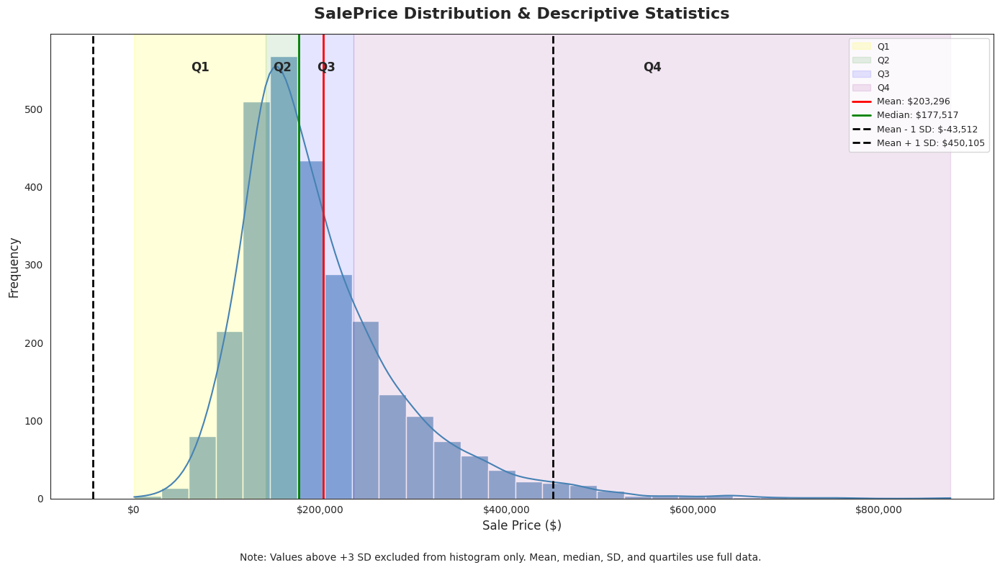

In [ ]:

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# =====================================
# 1. PREPARE DATA
# =====================================

sale_price_full = df["SalePrice"].dropna()

# Descriptive statistics from the full dataset
sale_mean = sale_price_full.mean()
sale_median = sale_price_full.median()
sale_std = sale_price_full.std()

sale_q1 = sale_price_full.quantile(0.25)
sale_q2 = sale_price_full.quantile(0.50)
sale_q3 = sale_price_full.quantile(0.75)

# Standard deviation boundaries
lower_sd = sale_mean - sale_std
upper_sd = sale_mean + sale_std

# =====================================
# 2. FILTER EXTREME OUTLIERS
# =====================================

# Exclude values above +3 SD from histogram only
upper_limit = sale_mean + (3 * sale_std)

sale_price_plot = sale_price_full[
    sale_price_full <= upper_limit
]

# =====================================
# 3. CREATE HISTOGRAM
# =====================================

sns.set_style("white")

fig, ax = plt.subplots(figsize=(14, 8))

sns.histplot(
    sale_price_plot,
    bins=30,
    kde=True,
    color="steelblue",
    alpha=0.6,
    edgecolor="white",
    ax=ax
)

ax.grid(False)

# =====================================
# 4. SHADE QUARTILES
# =====================================

ax.axvspan(
    sale_price_plot.min(), sale_q1,
    color="yellow",
    alpha=0.15,
    label="Q1"
)

ax.axvspan(
    sale_q1, sale_q2,
    color="green",
    alpha=0.10,
    label="Q2"
)

ax.axvspan(
    sale_q2, sale_q3,
    color="blue",
    alpha=0.10,
    label="Q3"
)

ax.axvspan(
    sale_q3, sale_price_plot.max(),
    color="purple",
    alpha=0.10,
    label="Q4"
)

# =====================================
# 5. ADD MEAN AND MEDIAN
# =====================================

ax.axvline(
    sale_mean,
    color="red",
    linewidth=2,
    label=f"Mean: ${sale_mean:,.0f}"
)

ax.axvline(
    sale_median,
    color="green",
    linewidth=2,
    label=f"Median: ${sale_median:,.0f}"
)

# =====================================
# 6. ADD STANDARD DEVIATION LINES
# =====================================

ax.axvline(
    lower_sd,
    color="black",
    linestyle="--",
    linewidth=2,
    label=f"Mean - 1 SD: ${lower_sd:,.0f}"
)

ax.axvline(
    upper_sd,
    color="black",
    linestyle="--",
    linewidth=2,
    label=f"Mean + 1 SD: ${upper_sd:,.0f}"
)

# =====================================
# 7. ADD QUARTILE LABELS
# =====================================

y_max = ax.get_ylim()[1]

quartile_positions = [
    (sale_price_plot.min() + sale_q1) / 2,
    (sale_q1 + sale_q2) / 2,
    (sale_q2 + sale_q3) / 2,
    (sale_q3 + sale_price_plot.max()) / 2
]

for label, x in zip(
    ["Q1", "Q2", "Q3", "Q4"],
    quartile_positions
):
    ax.text(
        x,
        y_max * 0.92,
        label,
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

# =====================================
# 8. FORMAT HISTOGRAM
# =====================================

ax.xaxis.set_major_formatter(
    mtick.StrMethodFormatter("${x:,.0f}")
)

ax.set_title(
    "SalePrice Distribution & Descriptive Statistics",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Sale Price ($)", fontsize=12)
ax.set_ylabel("Frequency", fontsize=12)

ax.legend(
    loc="upper right",
    fontsize=9,
    frameon=True
)

# =====================================
# 9. ADD EXPLANATORY NOTE
# =====================================

fig.text(
    0.5,
    0.02,
    "Note: Values above +3 SD excluded from histogram only. "
    "Mean, median, SD, and quartiles use full data.",
    ha="center",
    fontsize=10
)

plt.tight_layout(rect=[0, 0.05, 1, 1])

plt.show()


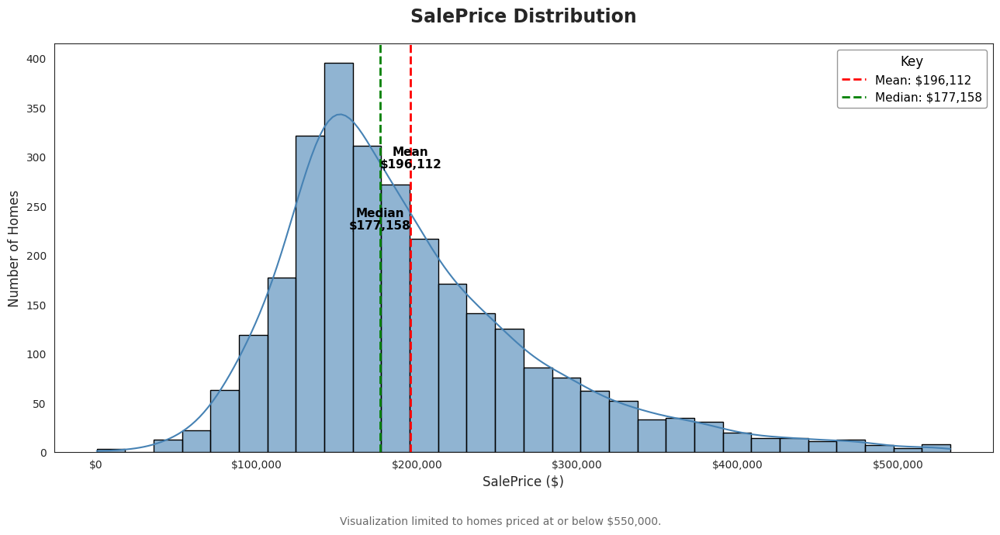

SALEPRICE DESCRIPTIVE STATISTICS
--------------------------------------------------
Original observations with SalePrice: 2,835
Observations displayed: 2,816
Percentage included: 99.3%
Mean: $196,111.81
Median: $177,158.33
Standard Deviation: $81,583.22
Minimum: $500.00
Maximum: $532,481.65
Q1 (25%): $141,891.60
Q2 (50%): $177,158.33
Q3 (75%): $234,151.06


In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mtick

# ----------------------------------------
# 1. ORIGINAL SALEPRICE DATA
# ----------------------------------------

sale_price_full = df["SalePrice"].dropna()

# ----------------------------------------
# 2. VISUALIZATION CUTOFF
# ----------------------------------------

# $550,000 cutoff for visualization only
# Does not affect regression models

cutoff = 550000

sale_price_plot = sale_price_full[
    sale_price_full <= cutoff
].copy()

# ----------------------------------------
# 3. DESCRIPTIVE STATISTICS
# ----------------------------------------

mean = sale_price_plot.mean()
median = sale_price_plot.median()
std = sale_price_plot.std()

q1 = sale_price_plot.quantile(0.25)
q2 = sale_price_plot.quantile(0.50)
q3 = sale_price_plot.quantile(0.75)

percentage = (
    len(sale_price_plot) / len(sale_price_full)
) * 100

# ----------------------------------------
# 4. CREATE HISTOGRAM
# ----------------------------------------

fig, ax = plt.subplots(figsize=(13, 7))

sns.histplot(
    x=sale_price_plot,
    bins=30,
    kde=True,
    color="steelblue",
    alpha=0.6,
    edgecolor="black",
    ax=ax
)

# ----------------------------------------
# 5. MEAN LINE - RED
# ----------------------------------------

ax.axvline(
    x=mean,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean: ${mean:,.0f}"
)

# ----------------------------------------
# 6. MEDIAN LINE - GREEN
# ----------------------------------------

ax.axvline(
    x=median,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Median: ${median:,.0f}"
)

# ----------------------------------------
# 7. BLACK LABELS ON THE LINES
# ----------------------------------------

# Mean label - RED line
ax.text(
    mean,
    0.72,
    f"Mean\n${mean:,.0f}",
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="center",
    color="black",
    fontsize=11,
    fontweight="bold",
    linespacing=1.1,
    zorder=10
)

# Median label - GREEN line
ax.text(
    median,
    0.57,
    f"Median\n${median:,.0f}",
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="center",
    color="black",
    fontsize=11,
    fontweight="bold",
    linespacing=1.1,
    zorder=10
)

# ----------------------------------------
# 8. ADD KEY (LEGEND)
# ----------------------------------------

legend = ax.legend(
    loc="upper right",
    title="Key",
    fontsize=11,
    title_fontsize=12,
    frameon=True,
    facecolor="white",
    edgecolor="gray"
)

for text in legend.get_texts():
    text.set_color("black")

legend.get_title().set_color("black")

# ----------------------------------------
# 9. FORMAT HISTOGRAM
# ----------------------------------------

ax.set_title(
    "SalePrice Distribution",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("SalePrice ($)", fontsize=12)
ax.set_ylabel("Number of Homes", fontsize=12)

ax.xaxis.set_major_formatter(
    mtick.StrMethodFormatter("${x:,.0f}")
)

# ----------------------------------------
# 10. ADD NOTE BELOW GRAPH
# ----------------------------------------

fig.text(
    0.5,
    0.025,
    "Visualization limited to homes priced at or below $550,000.",
    ha="center",
    fontsize=10,
    color="dimgray"
)

plt.tight_layout(rect=[0, 0.07, 1, 1])

# ----------------------------------------
# 11. DISPLAY HISTOGRAM
# ----------------------------------------

plt.show()

# ----------------------------------------
# 12. PRINT DESCRIPTIVE STATISTICS
# ----------------------------------------

print("SALEPRICE DESCRIPTIVE STATISTICS")
print("-" * 50)

print(f"Original observations with SalePrice: {len(sale_price_full):,}")
print(f"Observations displayed: {len(sale_price_plot):,}")
print(f"Percentage included: {percentage:.1f}%")

print(f"Mean: ${mean:,.2f}")
print(f"Median: ${median:,.2f}")
print(f"Standard Deviation: ${std:,.2f}")

print(f"Minimum: ${sale_price_plot.min():,.2f}")
print(f"Maximum: ${sale_price_plot.max():,.2f}")

print(f"Q1 (25%): ${q1:,.2f}")
print(f"Q2 (50%): ${q2:,.2f}")
print(f"Q3 (75%): ${q3:,.2f}")



AI Disclosure: I used Copilot and google to assist with creating some of the Python code for my bar chart. I reviewed the code, ran the analysis, and completed the interpretation of the results myself.

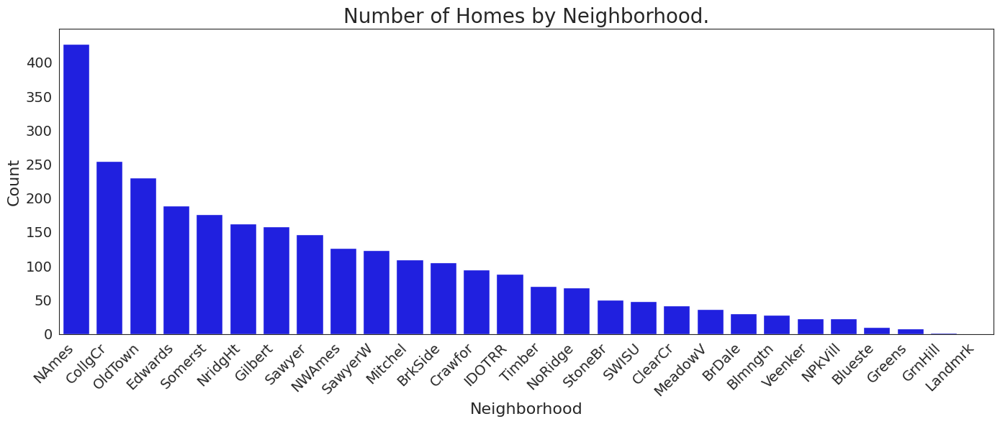

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

column = 'Neighborhood'
counts = df[column].value_counts()

plt.figure(figsize=(14,6))
sns.barplot(x=counts.index, y=counts.values, color='blue')

# Bigger text sizes
plt.title("Number of Homes by Neighborhood.", fontsize=20)
plt.xlabel("Neighborhood", fontsize=16)
plt.ylabel("Count", fontsize=16)

# Bigger tick labels
plt.xticks(rotation=45, ha='right', fontsize=14)
plt.yticks(fontsize=14)

plt.tight_layout()
plt.show()


In [ ]:
# Notice how the view changes using a print() statement
print(descriptive_statistics_view)

                 PID  MS SubClass  Lot Frontage   Lot Area  Overall Qual  \
count       2,836.00     2,835.00      2,366.00   2,835.00      2,835.00   
mean  713,663,085.28        57.51         69.25  10,125.43          6.10   
std   188,639,896.97        42.84         23.51   7,918.30          1.41   
min   526,301,100.00        20.00         21.00   1,300.00          1.00   
25%   528,458,127.50        20.00         58.00   7,417.50          5.00   
50%   535,453,125.00        50.00         68.00   9,399.00          6.00   
75%   907,180,362.50        70.00         80.00  11,539.50          7.00   
max   924,151,040.00       190.00        313.00 215,245.00         10.00   

       Overall Cond  Year Built  Year Remod/Add  Mas Vnr Area  BsmtFin SF 1  \
count      2,835.00    2,835.00        2,835.00      2,813.00      2,834.00   
mean           5.56    1,986.52        1,999.36        102.90        444.80   
std            1.11       30.18           20.84        179.90        456.45   

In [ ]:
# Notice how the view changes using a display statement
display(descriptive_statistics_view)

,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,TotRms AbvGrd,Fireplaces,Garage Yr Blt,Garage Cars,Garage Area,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
count,"2,836.00","2,835.00","2,366.00","2,835.00","2,835.00","2,835.00","2,835.00","2,835.00","2,813.00","2,834.00","2,834.00","2,834.00","2,834.00","2,835.00","2,835.00","2,835.00","2,835.00","2,833.00","2,833.00","2,835.00","2,835.00","2,835.00","2,835.00","2,835.00","2,835.00","2,677.00","2,834.00","2,834.00","2,835.00","2,835.00","2,835.00","2,835.00","2,835.00","2,835.00","2,835.00","2,835.00","2,835.00","2,835.00"
mean,"713,663,085.28",57.51,69.25,"10,125.43",6.10,5.56,"1,986.52","1,999.36",102.90,444.80,49.49,559.32,"1,053.62","1,159.51",333.40,4.64,"1,497.54",0.43,0.06,1.57,0.38,2.85,1.05,6.44,0.60,"1,796.36",1.76,472.76,94.77,47.48,22.85,2.68,16.11,2.12,51.63,6.20,"2,022.78","203,296.10"
std,"188,639,896.97",42.84,23.51,"7,918.30",1.41,1.11,30.18,20.84,179.90,456.45,168.67,441.17,442.05,392.59,428.55,46.32,506.30,0.53,0.25,0.55,0.50,0.83,0.22,1.57,0.64,25.87,0.77,216.65,126.45,67.56,64.13,25.55,56.47,34.54,574.98,2.71,1.38,"246,808.48"
min,"526,301,100.00",20.00,21.00,"1,300.00",1.00,1.00,"1,887.00","1,956.00",0.00,0.00,0.00,0.00,0.00,334.00,0.00,0.00,334.00,0.00,0.00,0.00,0.00,0.00,0.00,2.00,0.00,"1,713.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,"2,006.00",500.00
25%,"528,458,127.50",20.00,58.00,"7,417.50",5.00,5.00,"1,969.00","1,980.00",0.00,0.00,0.00,219.00,793.00,877.50,0.00,0.00,"1,122.50",0.00,0.00,1.00,0.00,2.00,1.00,5.00,0.00,"1,779.00",1.00,319.25,0.00,0.00,0.00,0.00,0.00,0.00,0.00,4.00,"2,022.00","142,044.67"
50%,"535,453,125.00",50.00,68.00,"9,399.00",6.00,5.00,"1,989.00","2,008.00",0.00,372.50,0.00,461.00,991.50,"1,084.00",0.00,0.00,"1,440.00",0.00,0.00,2.00,0.00,3.00,1.00,6.00,1.00,"1,797.00",2.00,480.00,0.00,26.00,0.00,0.00,0.00,0.00,0.00,6.00,"2,023.00","177,516.71"
75%,"907,180,362.50",70.00,80.00,"11,539.50",7.00,6.00,"2,016.00","2,019.00",166.00,737.00,0.00,801.00,"1,303.50","1,384.00",702.00,0.00,"1,742.00",1.00,0.00,2.00,1.00,3.00,1.00,7.00,1.00,"1,820.00",2.00,576.00,168.00,70.00,0.00,0.00,0.00,0.00,0.00,8.00,"2,024.00","236,069.06"
max,"924,151,040.00",190.00,313.00,"215,245.00",10.00,9.00,"2,025.00","2,025.00","1,600.00","5,644.00","1,526.00","2,336.00","6,110.00","5,095.00","2,065.00","1,064.00","5,642.00",3.00,2.00,4.00,2.00,8.00,3.00,15.00,4.00,"2,025.00",5.00,"1,488.00","1,424.00",742.00,"1,012.00",508.00,576.00,800.00,"17,000.00",12.00,"2,025.00","12,455,000.00"


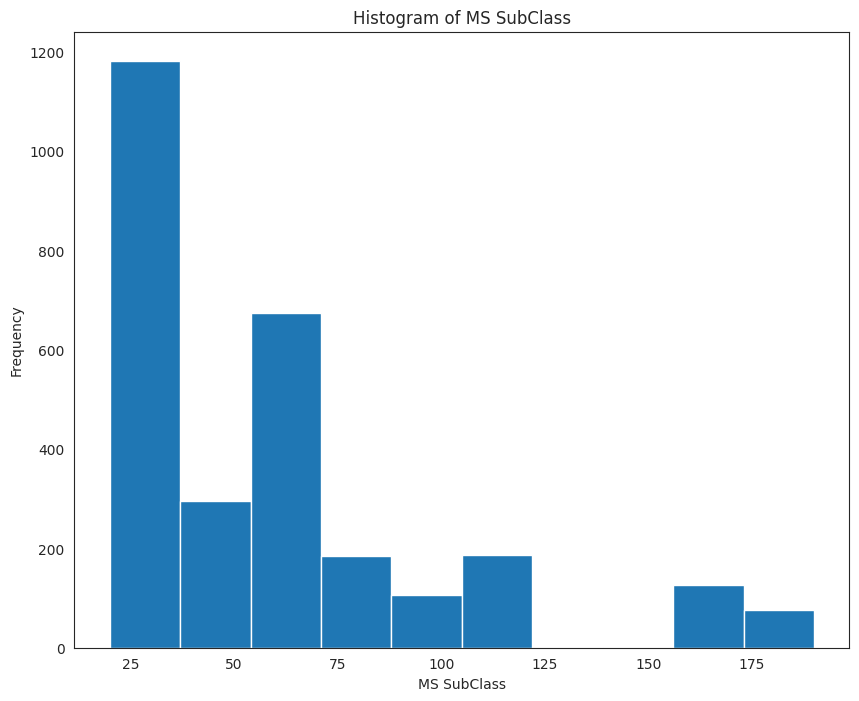

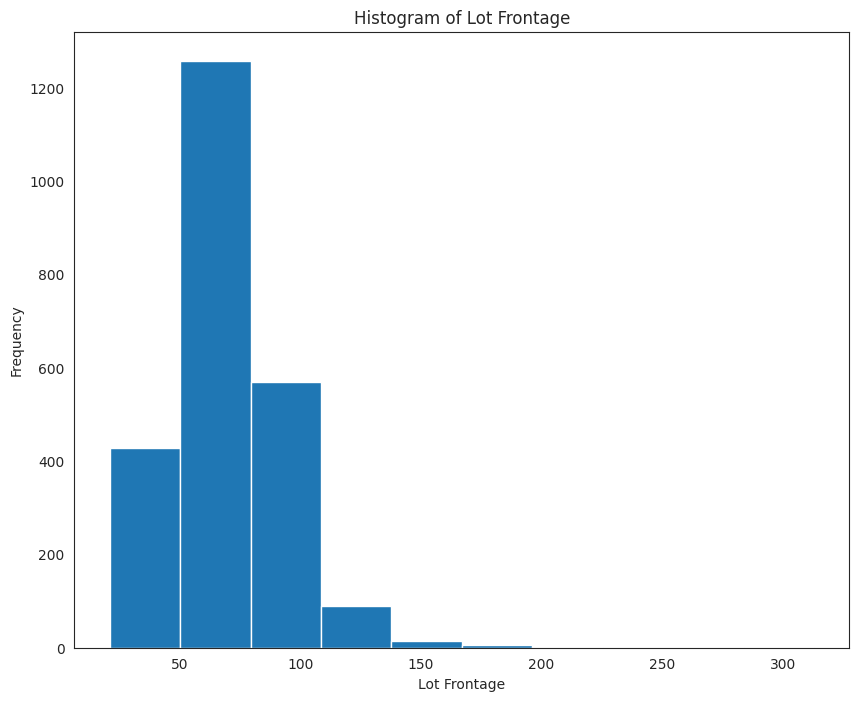

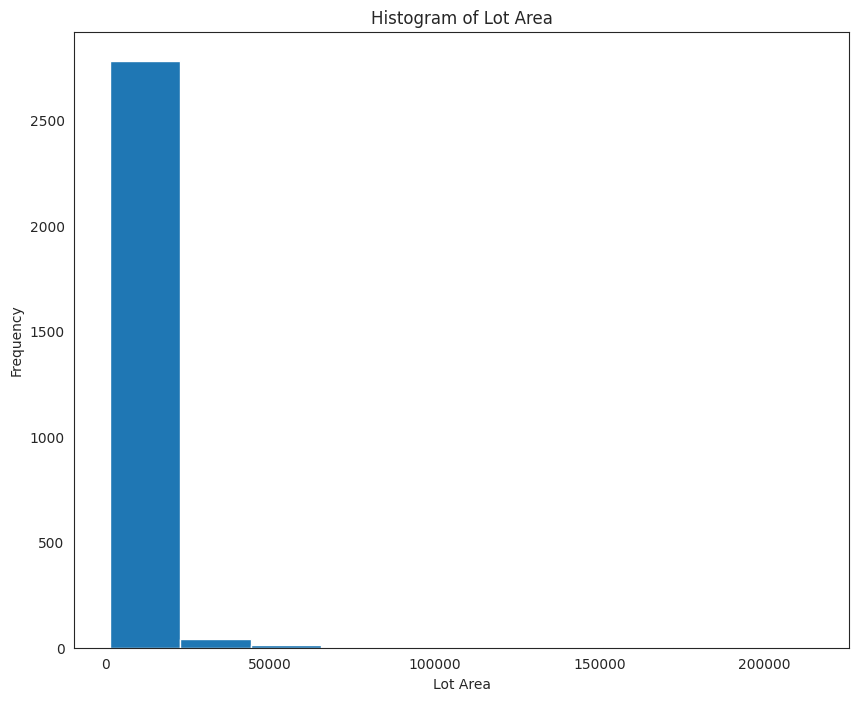

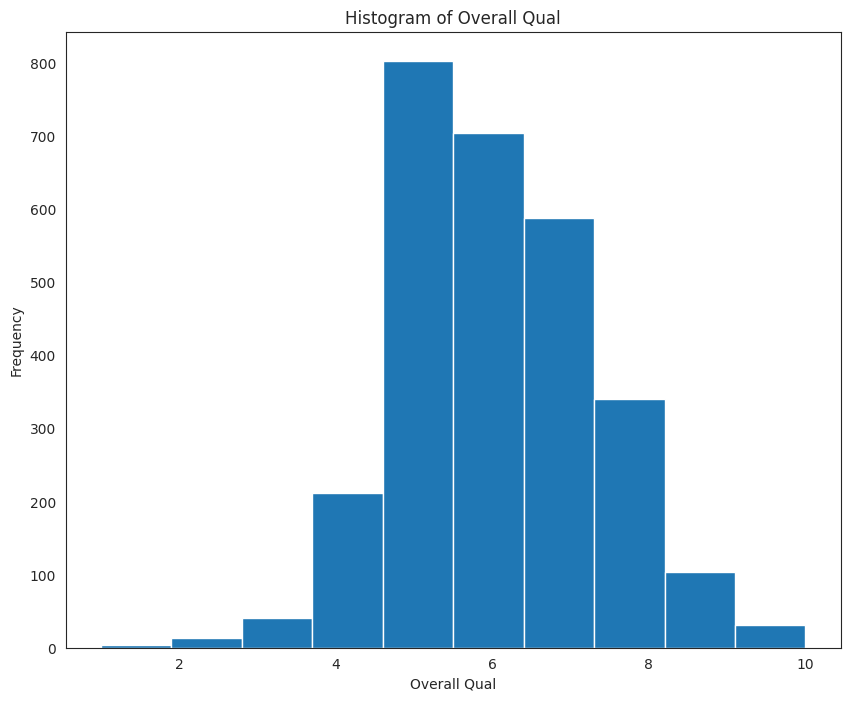

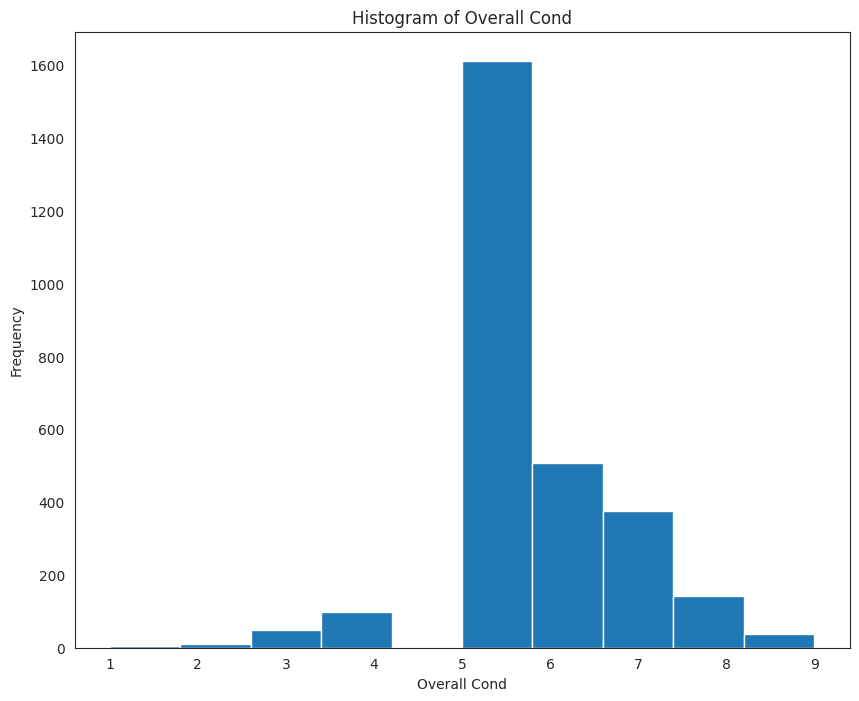

...

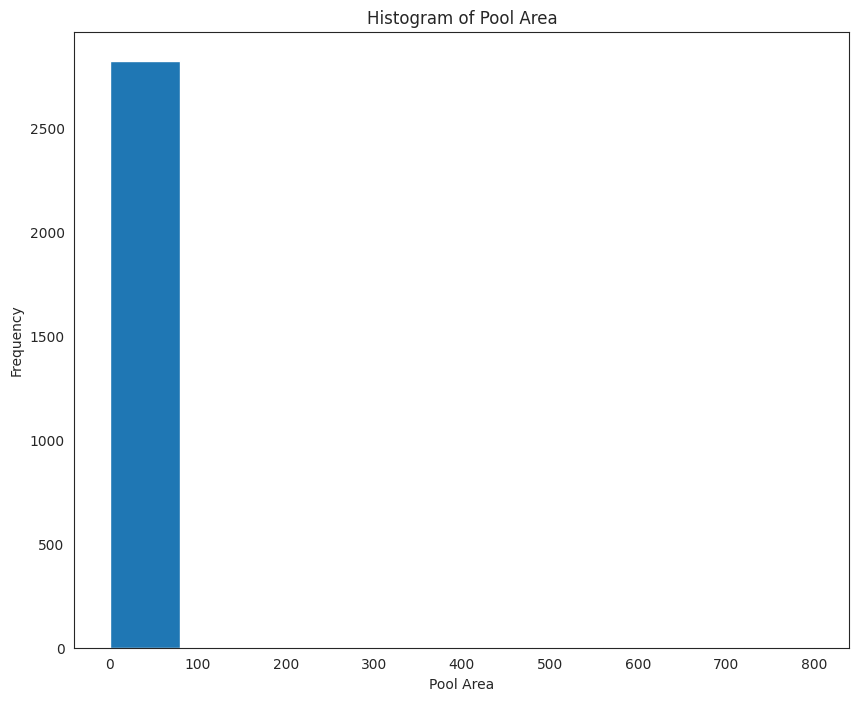

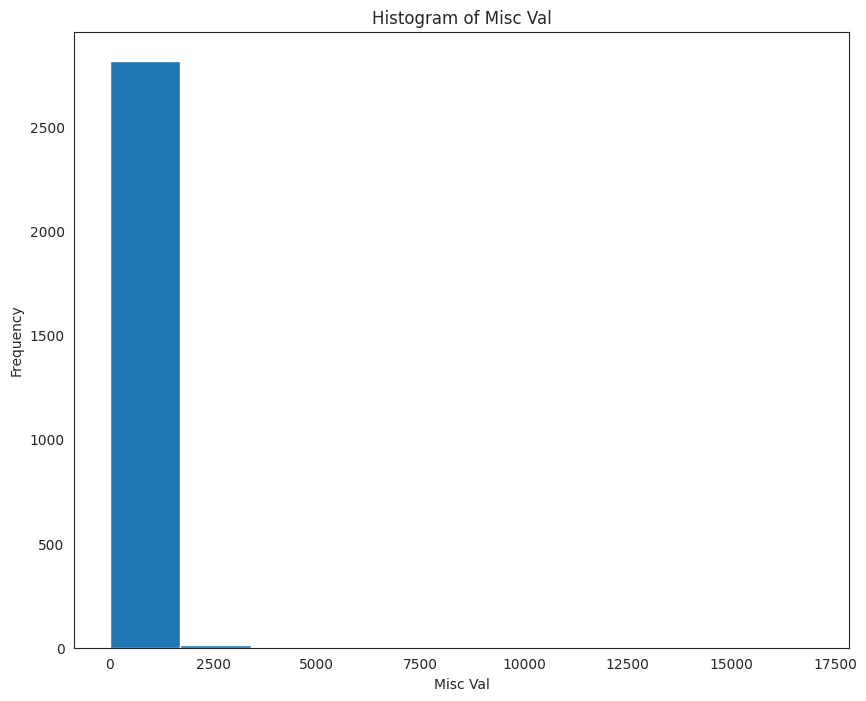

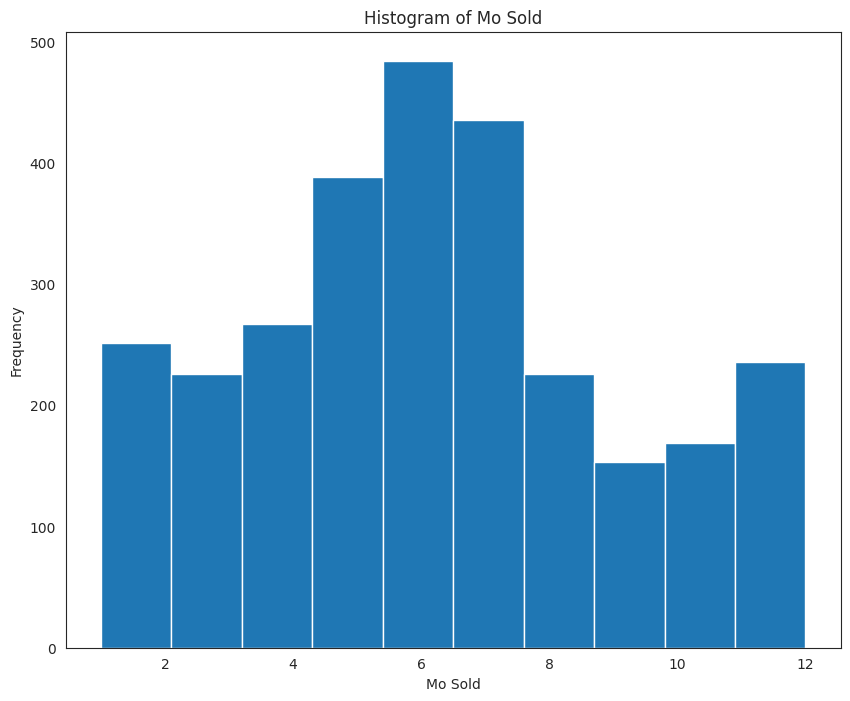

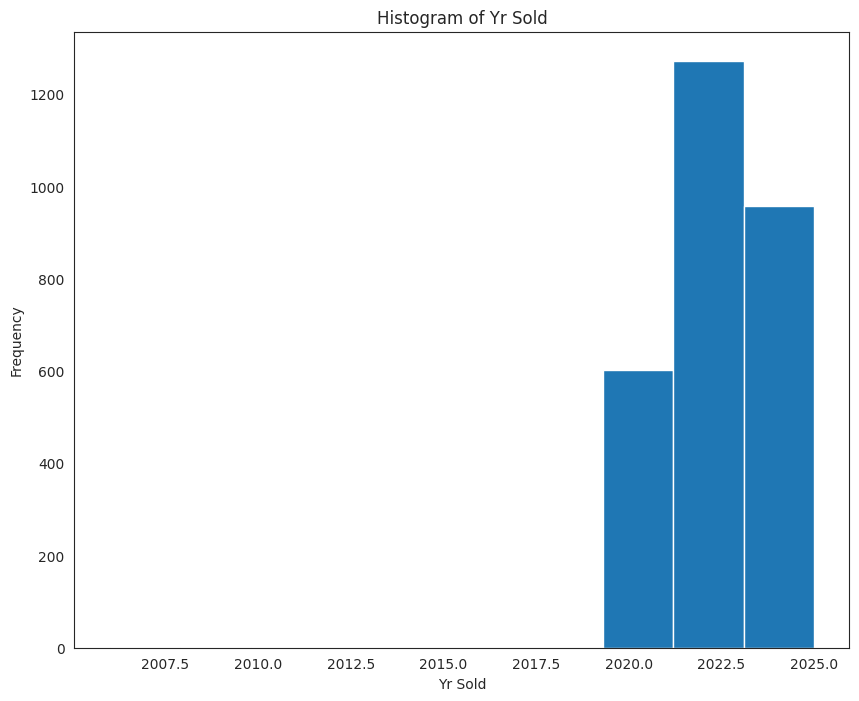

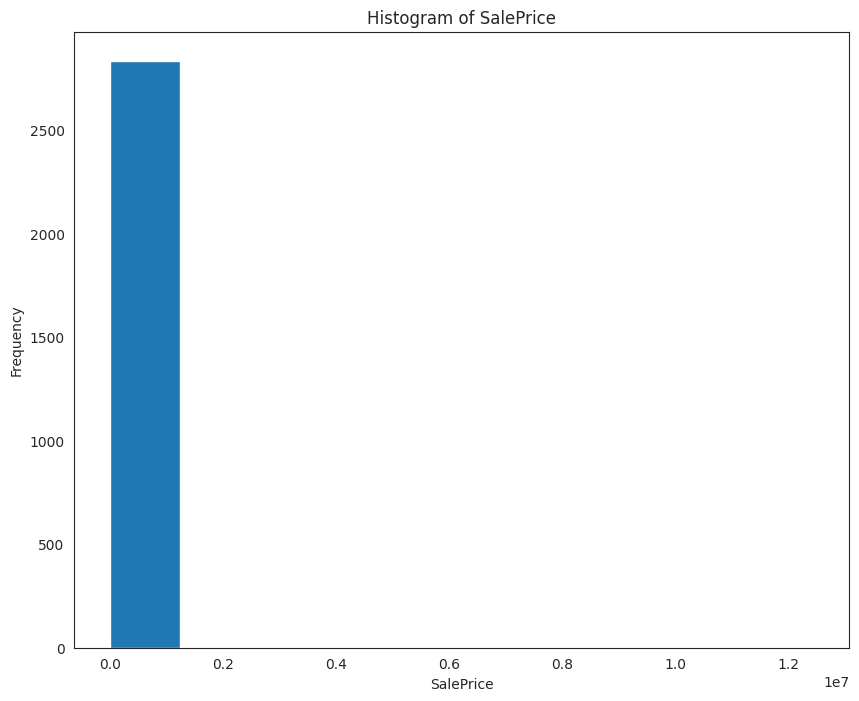

In [ ]:

import matplotlib.pyplot as plt

# Select numerical columns and exclude PID if present
numeric_df = df.select_dtypes(include="number").drop(
    columns=["PID"],
    errors="ignore"
)

# Create histograms
for col in numeric_df.columns:
    plt.figure(figsize=(10, 8))
    plt.hist(numeric_df[col].dropna(), bins=10)
    plt.title(f"Histogram of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()


In [ ]:
# prompt: review df for a list of multiple variable names from a list and drops the variables from the df. the defualt list is just one variable 'RecordID'
# NOTE, this was my third prompt. The first two were so vague that Gemini had a **very** long function.
"""
Generative AI code will often build a function. This is great because it is reusable within the notebook or can be brought over to another.
It is important that the function is run. That is best done in a seperate cell after the function is defined.
"""
def drop_variables(df, variables_to_drop=['RecordID']):
    """
    Reviews a Pandas DataFrame for a list of variable names and drops them.

    Args:
        df: The input DataFrame.
        variables_to_drop: A list of variable names to drop. Defaults to ['RecordID'].

    Returns:
        A new DataFrame with the specified variables removed, or the original DataFrame if no variables are found.
        Prints a message indicating which variables were dropped or if none were found.
    """

    variables_dropped = []             # defines an empty list to add dropped variables to
    for var in variables_to_drop:      # for loop to look at each varible in the list
        if var in df.columns:          # if test to look if the variable name is in the dataframe's columns
            df = df.drop(var, axis=1)  # drop the variable from the dataframe
            variables_dropped.append(var)  # add the variable to the list of dropped variables

    if variables_dropped:   # if test defaults to "TRUE" so if the list is not blank, it will do the rest of the if statement
        print(f"Variables dropped: {variables_dropped}")
    else:                   # else statements are optional, but should be used
        print("No variables to drop found in the DataFrame.")

    # Final Notes:
    """
    Gemini did not identify the much simplier way to do this.
    However, this one line of code does not build or report the variables_dropped list.
    """
    # df = df.drop(variables_to_drop, errors= 'ignore', axis=1)
    """ This is how it would look in a production enviornment, to prvent the extra memory needed to overwrite the df. """
    # df.drop(columns=variables_to_drop, errors='ignore', inplace=True) # `axis=1` indicates columns and removed because it is the default, therefore not needed

    return df               # identifies that the fucntion returns the original df modified


In [ ]:
# descriptive statistics
# understanding the descriptive statistics for the full dataset will help use set a benchmark for future comparision
df.describe()

,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,TotRms AbvGrd,Fireplaces,Garage Yr Blt,Garage Cars,Garage Area,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
count,"2,836.00","2,835.00","2,366.00","2,835.00","2,835.00","2,835.00","2,835.00","2,835.00","2,813.00","2,834.00","2,834.00","2,834.00","2,834.00","2,835.00","2,835.00","2,835.00","2,835.00","2,833.00","2,833.00","2,835.00","2,835.00","2,835.00","2,835.00","2,835.00","2,835.00","2,677.00","2,834.00","2,834.00","2,835.00","2,835.00","2,835.00","2,835.00","2,835.00","2,835.00","2,835.00","2,835.00","2,835.00","2,835.00"
mean,"713,663,085.28",57.51,69.25,"10,125.43",6.10,5.56,"1,986.52","1,999.36",102.90,444.80,49.49,559.32,"1,053.62","1,159.51",333.40,4.64,"1,497.54",0.43,0.06,1.57,0.38,2.85,1.05,6.44,0.60,"1,796.36",1.76,472.76,94.77,47.48,22.85,2.68,16.11,2.12,51.63,6.20,"2,022.78","203,296.10"
std,"188,639,896.97",42.84,23.51,"7,918.30",1.41,1.11,30.18,20.84,179.90,456.45,168.67,441.17,442.05,392.59,428.55,46.32,506.30,0.53,0.25,0.55,0.50,0.83,0.22,1.57,0.64,25.87,0.77,216.65,126.45,67.56,64.13,25.55,56.47,34.54,574.98,2.71,1.38,"246,808.48"
min,"526,301,100.00",20.00,21.00,"1,300.00",1.00,1.00,"1,887.00","1,956.00",0.00,0.00,0.00,0.00,0.00,334.00,0.00,0.00,334.00,0.00,0.00,0.00,0.00,0.00,0.00,2.00,0.00,"1,713.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,"2,006.00",500.00
25%,"528,458,127.50",20.00,58.00,"7,417.50",5.00,5.00,"1,969.00","1,980.00",0.00,0.00,0.00,219.00,793.00,877.50,0.00,0.00,"1,122.50",0.00,0.00,1.00,0.00,2.00,1.00,5.00,0.00,"1,779.00",1.00,319.25,0.00,0.00,0.00,0.00,0.00,0.00,0.00,4.00,"2,022.00","142,044.67"
50%,"535,453,125.00",50.00,68.00,"9,399.00",6.00,5.00,"1,989.00","2,008.00",0.00,372.50,0.00,461.00,991.50,"1,084.00",0.00,0.00,"1,440.00",0.00,0.00,2.00,0.00,3.00,1.00,6.00,1.00,"1,797.00",2.00,480.00,0.00,26.00,0.00,0.00,0.00,0.00,0.00,6.00,"2,023.00","177,516.71"
75%,"907,180,362.50",70.00,80.00,"11,539.50",7.00,6.00,"2,016.00","2,019.00",166.00,737.00,0.00,801.00,"1,303.50","1,384.00",702.00,0.00,"1,742.00",1.00,0.00,2.00,1.00,3.00,1.00,7.00,1.00,"1,820.00",2.00,576.00,168.00,70.00,0.00,0.00,0.00,0.00,0.00,8.00,"2,024.00","236,069.06"
max,"924,151,040.00",190.00,313.00,"215,245.00",10.00,9.00,"2,025.00","2,025.00","1,600.00","5,644.00","1,526.00","2,336.00","6,110.00","5,095.00","2,065.00","1,064.00","5,642.00",3.00,2.00,4.00,2.00,8.00,3.00,15.00,4.00,"2,025.00",5.00,"1,488.00","1,424.00",742.00,"1,012.00",508.00,576.00,800.00,"17,000.00",12.00,"2,025.00","12,455,000.00"


In [ ]:
df[['SalePrice', 'Overall Qual', 'Lot Area',
    'Year Built', 'Total Bsmt SF']].describe()

,SalePrice,Overall Qual,Lot Area,Year Built,Total Bsmt SF
count,"2,835.00","2,835.00","2,835.00","2,835.00","2,834.00"
mean,"203,296.10",6.10,"10,125.43","1,986.52","1,053.62"
std,"246,808.48",1.41,"7,918.30",30.18,442.05
min,500.00,1.00,"1,300.00","1,887.00",0.00
25%,"142,044.67",5.00,"7,417.50","1,969.00",793.00
50%,"177,516.71",6.00,"9,399.00","1,989.00",991.50
75%,"236,069.06",7.00,"11,539.50","2,016.00","1,303.50"
max,"12,455,000.00",10.00,"215,245.00","2,025.00","6,110.00"


In [ ]:
# Call the dataframe to show the variables and open Interactive table in Colab
# NOTE, if you scroll all the way to the right in Colab,
#    click the Table icon to view an "interactive sheet" that acts like an excel spreadsheet.
# The plot icon will generate many suggested plots, only some of them are worth using in your analysis.
df
# After you you run and view your df, you should see the "Next steps:" options under the datframe output. These are wise to use for the very first steps of your EDA.
# After you you "View recommended plots", be sure to dig deeper with your own plots

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice,Neighborhood_Grouped
0,916382010,60.00,RL,83.00,"13,159.00",Pave,NaN,IR1,HLS,AllPub,Corner,Gtl,Timber,Norm,Norm,1Fam,2Story,7.00,5.00,"2,024.00","2,024.00",Gable,CompShg,VinylSd,VinylSd,NaN,0.00,TA,TA,PConc,Ex,TA,Av,Unf,0.00,Unf,0.00,846.00,846.00,GasA,Gd,Y,SBrkr,846.00,846.00,0.00,"1,692.00",0.00,0.00,2.00,1.00,3.00,1.00,Gd,6.00,Typ,0.00,NaN,Attchd,"1,827.00",RFn,2.00,650.00,TA,TA,Y,208.00,114.00,0.00,0.00,0.00,0.00,NaN,NaN,NaN,0.00,7.00,"2,024.00",New,Partial,"250,669.69",Timber
1,902102100,50.00,RM,60.00,"4,800.00",Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,OldTown,Norm,Norm,1Fam,1.5Fin,4.00,5.00,"1,915.00","1,969.00",Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,771.00,TA,TA,PConc,TA,TA,No,ALQ,48.00,Unf,0.00,661.00,709.00,GasA,TA,Y,SBrkr,"1,157.00",687.00,0.00,"1,844.00",1.00,0.00,1.00,0.00,3.00,1.00,TA,9.00,Min2,2.00,Gd,Basment,"1,718.00",Unf,1.00,240.00,TA,TA,Y,84.00,0.00,0.00,0.00,0.00,0.00,NaN,NaN,NaN,0.00,1.00,"2,025.00",COD,Abnorml,"92,291.33",OldTown
2,902305090,70.00,RM,60.00,"9,600.00",Pave,Grvl,Reg,Lvl,AllPub,Inside,Gtl,OldTown,Norm,Norm,1Fam,2Story,4.00,2.00,"1,915.00","1,965.00",Gable,CompShg,AsbShng,Stucco,NaN,0.00,TA,TA,BrkTil,TA,Fa,No,Unf,0.00,Unf,0.00,"1,095.00","1,095.00",GasW,Fa,N,SBrkr,"1,095.00",679.00,0.00,"1,774.00",1.00,0.00,2.00,0.00,4.00,2.00,TA,8.00,Min2,0.00,NaN,2Types,"1,738.00",Unf,3.00,779.00,Fa,Fa,N,0.00,0.00,90.00,0.00,0.00,0.00,NaN,NaN,NaN,0.00,5.00,"2,021.00",WD,Normal,"92,106.04",OldTown
3,532377060,20.00,RL,NaN,"9,819.00",Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Sawyer,Norm,Norm,1Fam,1Story,5.00,5.00,"1,982.00","1,982.00",Gable,CompShg,MetalSd,MetalSd,BrkFace,31.00,TA,Gd,CBlock,TA,TA,No,BLQ,450.00,Unf,0.00,432.00,882.00,GasA,TA,Y,SBrkr,900.00,0.00,0.00,900.00,0.00,0.00,1.00,0.00,3.00,1.00,TA,5.00,Typ,0.00,NaN,Detchd,"1,788.00",Unf,1.00,280.00,TA,TA,Y,0.00,0.00,0.00,0.00,0.00,0.00,NaN,MnPrv,NaN,0.00,2.00,"2,025.00",WD,Normal,"125,639.95",Sawyer
4,528344060,60.00,RL,78.00,"12,011.00",Pave,NaN,IR1,Lvl,AllPub,CulDSac,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8.00,5.00,"2,013.00","2,013.00",Gable,CompShg,VinylSd,VinylSd,BrkFace,530.00,Gd,TA,PConc,Gd,TA,Av,GLQ,956.00,Unf,0.00,130.00,"1,086.00",GasA,Ex,Y,SBrkr,"1,086.00",838.00,0.00,"1,924.00",1.00,0.00,2.00,1.00,3.00,1.00,Gd,7.00,Typ,1.00,TA,Attchd,"1,816.00",RFn,2.00,592.00,TA,TA,Y,208.00,75.00,0.00,0.00,374.00,0.00,NaN,NaN,NaN,0.00,6.00,"2,021.00",WD,Normal,"284,934.11",NoRidge
5,923125030,20.00,A (agr),125.00,"31,250.00",Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Mitchel,Artery,Norm,1Fam,1Story,1.00,3.00,"1,966.00","1,966.00",Gable,CompShg,CBlock,VinylSd,NaN,0.00,TA,Fa,CBlock,NaN,NaN,NaN,NaN,0.00,NaN,0.00,0.00,0.00,GasA,TA,Y,FuseA,"1,600.00",0.00,0.00,"1,600.00",0.00,0.00,1.00,1.00,3.00,1.00,TA,6.00,Mod,0.00,NaN,Attchd,"1,769.00",Unf,1.00,270.00,Fa,TA,N,0.00,0.00,135.00,0.00,0.00,0.00,NaN,NaN,NaN,0.00,5.00,"2,021.00",WD,Normal,"91,454.26",Mitchel
6,903228080,50.00,RM,60.00,"6,000.00",Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,BrkSide,Norm,Norm,1Fam,1.5Fin,6.00,6.00,"1,956.00","1,965.00",Gable,CompShg,Wd Sdng,Wd Sdng,NaN,0.00,TA,Gd,BrkTil,TA,Gd,No,ALQ,375.00,Unf

## Visualizations with matplotlib

AI Disclosure: I used Google Colab AI to assist with creating some of the Python code for my scatteplot. I reviewed the code, ran the analysis, and completed the interpretation of the results myself.

In [ ]:
import matplotlib.ticker as mtick
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick


In [ ]:
df.nlargest(10, "SalePrice")[["SalePrice", "Neighborhood"]]

,SalePrice,Neighborhood
2835,"12,455,000.00",NAmes
899,"876,575.71",NoRidge
409,"759,615.09",NoRidge
2284,"729,141.96",NridgHt
656,"693,290.80",NoRidge
1460,"672,564.22",StoneBr
2378,"654,204.83",NridgHt
2414,"647,065.86",StoneBr
715,"640,033.63",NoRidge
956,"637,778.13",NridgHt


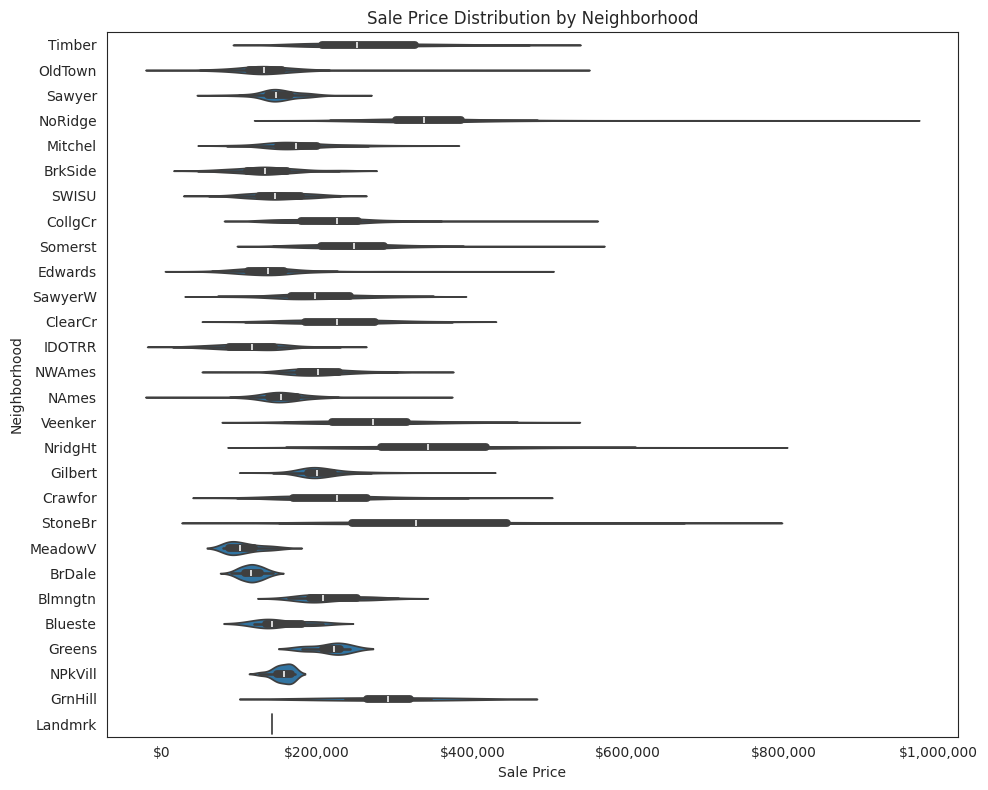

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import StrMethodFormatter

# Create violin plot using cleaned dataset
plt.figure(figsize=(10, 8))

sns.violinplot(
data=df_filtered,    x="SalePrice",
    y="Neighborhood"
)

# Format SalePrice as dollars
plt.gca().xaxis.set_major_formatter(
    StrMethodFormatter('${x:,.0f}')
)

# Add labels and title
plt.xlabel("Sale Price")
plt.ylabel("Neighborhood")
plt.title("Sale Price Distribution by Neighborhood")

plt.tight_layout()
plt.show()

## Visualizations with seaborn

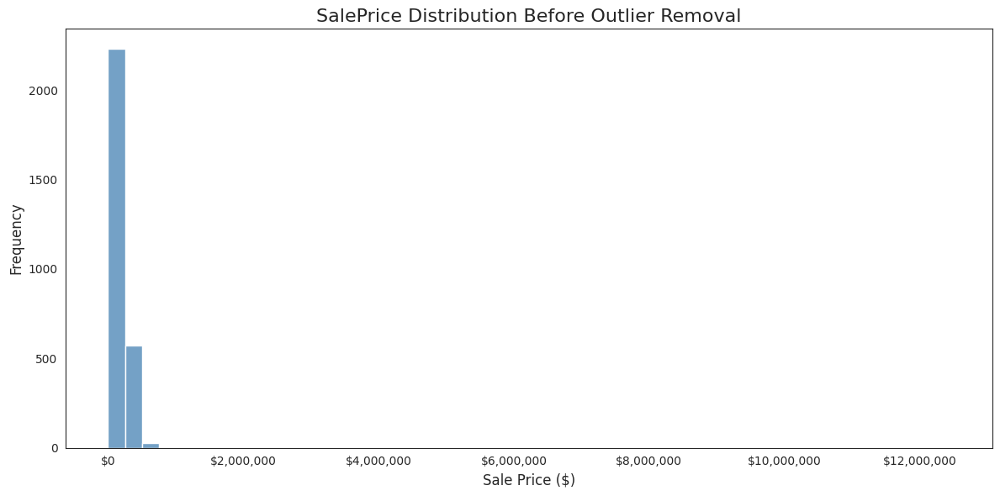

Original observations: 2836
Maximum SalePrice: 12455000.0


In [ ]:
# ==========================================
# SALEPRICE DISTRIBUTION - BEFORE OUTLIER REMOVAL
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import StrMethodFormatter

# Use original dataset (includes $12.5M outlier)
df_original = df.copy()

# Create histogram
fig, ax = plt.subplots(figsize=(12, 6))

sns.histplot(
    data=df_original,
    x="SalePrice",
    bins=50,
    color="steelblue",
    edgecolor="white",
    ax=ax
)

# Titles and labels
ax.set_title(
    "SalePrice Distribution Before Outlier Removal",
    fontsize=16
)
ax.set_xlabel("Sale Price ($)", fontsize=12)
ax.set_ylabel("Frequency", fontsize=12)

# Format X-axis as dollars
ax.xaxis.set_major_formatter(
    StrMethodFormatter('${x:,.0f}')
)

# Remove gridlines
ax.grid(False)

# White background
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

plt.tight_layout()
plt.show()

# Verify original dataset
print("Original observations:", len(df_original))
print("Maximum SalePrice:", df_original["SalePrice"].max())

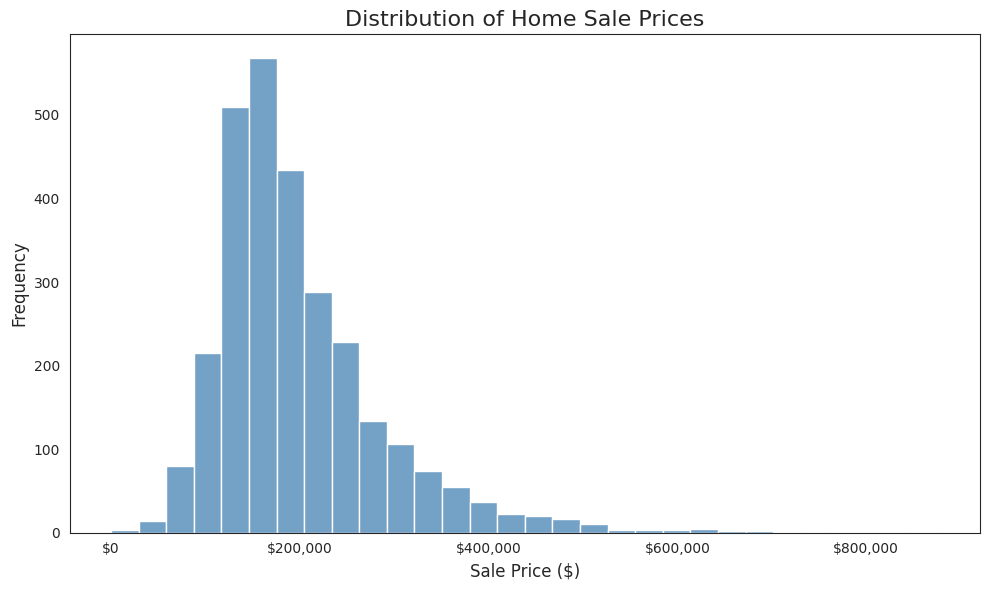

Observations used: 2834
Maximum SalePrice: 876575.7140416516


In [ ]:
# ==========================================
# SALEPRICE DISTRIBUTION - FILTERED DATASET
# ==========================================

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Use filtered dataset (2 extreme outliers removed)
df_hist = df_filtered.copy()

# Create histogram
fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(
    data=df_hist,
    x="SalePrice",
    bins=30,
    color="steelblue",
    edgecolor="white",
    ax=ax
)

# Titles and labels
ax.set_title("Distribution of Home Sale Prices", fontsize=16)
ax.set_xlabel("Sale Price ($)", fontsize=12)
ax.set_ylabel("Frequency", fontsize=12)

# Format horizontal axis as dollars
ax.xaxis.set_major_formatter(
    StrMethodFormatter('${x:,.0f}')
)

# Remove gridlines
ax.grid(False)

# White background
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

plt.tight_layout()
plt.show()

# Verify dataset
print("Observations used:", len(df_hist))
print("Maximum SalePrice:", df_hist["SalePrice"].max())

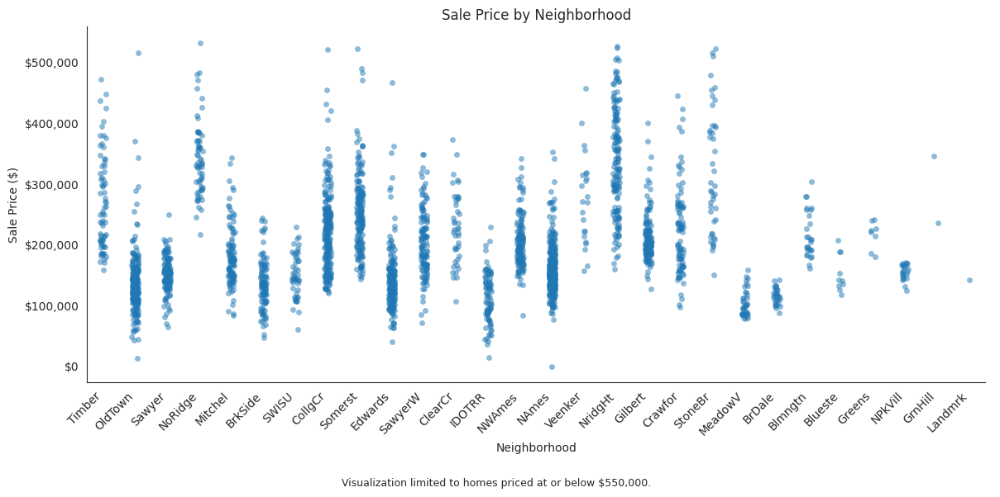

In [ ]:

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Filter for visualization only
df_plot = df[
    (df["SalePrice"] > 0) &
    (df["SalePrice"] <= 550000)
].copy()

# Create neighborhood strip plot
sns.catplot(
    data=df_plot,
    x="Neighborhood",
    y="SalePrice",
    kind="strip",
    height=6,
    aspect=2,
    alpha=0.5
)

plt.xticks(rotation=45, ha="right")
plt.title("Sale Price by Neighborhood")
plt.xlabel("Neighborhood")
plt.ylabel("Sale Price ($)")

# Format prices as dollars
plt.gca().yaxis.set_major_formatter(
    StrMethodFormatter("${x:,.0f}")
)

plt.figtext(
    0.5, 0.01,
    "Visualization limited to homes priced at or below $550,000.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()


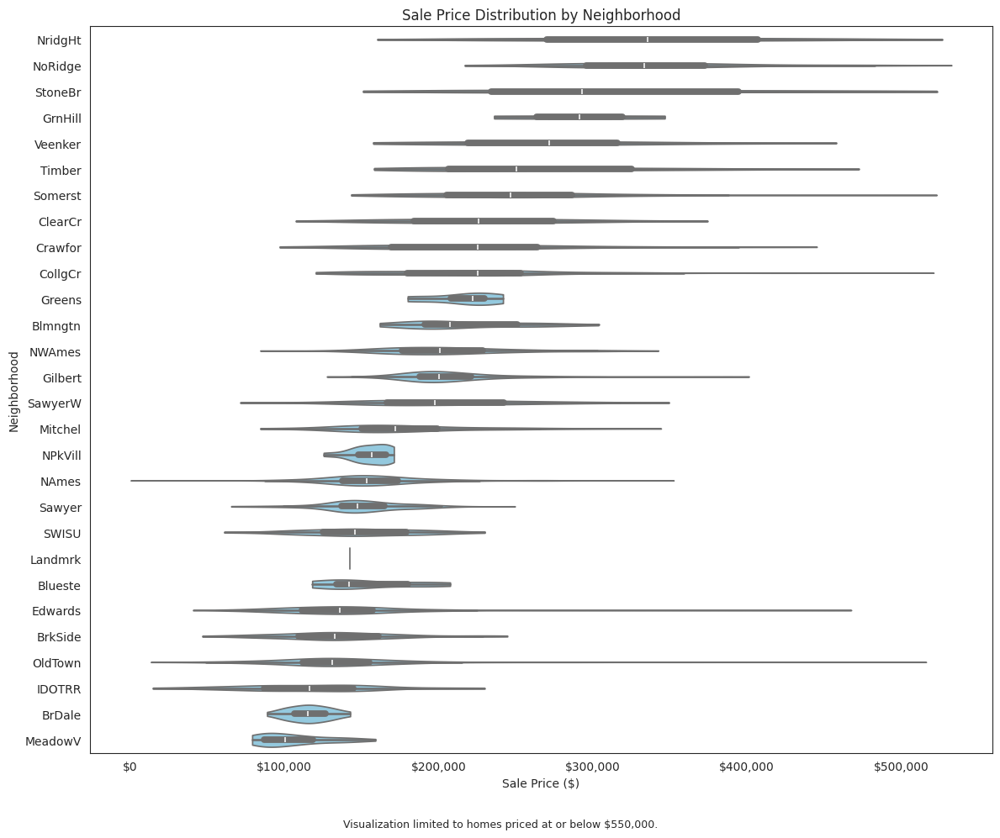

In [ ]:

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Create visualization-only dataset
df_violin = df[
    (df["SalePrice"] > 0) &
    (df["SalePrice"] <= 550000)
].copy()

# Order neighborhoods by median SalePrice
order = (
    df_violin.groupby("Neighborhood")["SalePrice"]
    .median()
    .sort_values(ascending=False)
    .index
)

# Create horizontal violin plot
plt.figure(figsize=(12, 10))

sns.violinplot(
    data=df_violin,
    x="SalePrice",
    y="Neighborhood",
    order=order,
    color="skyblue",
    inner="box",
    cut=0
)

# Format dollar values
plt.gca().xaxis.set_major_formatter(
    StrMethodFormatter("${x:,.0f}")
)

plt.title("Sale Price Distribution by Neighborhood")
plt.xlabel("Sale Price ($)")
plt.ylabel("Neighborhood")

plt.figtext(
    0.5, 0.01,
    "Visualization limited to homes priced at or below $550,000.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()


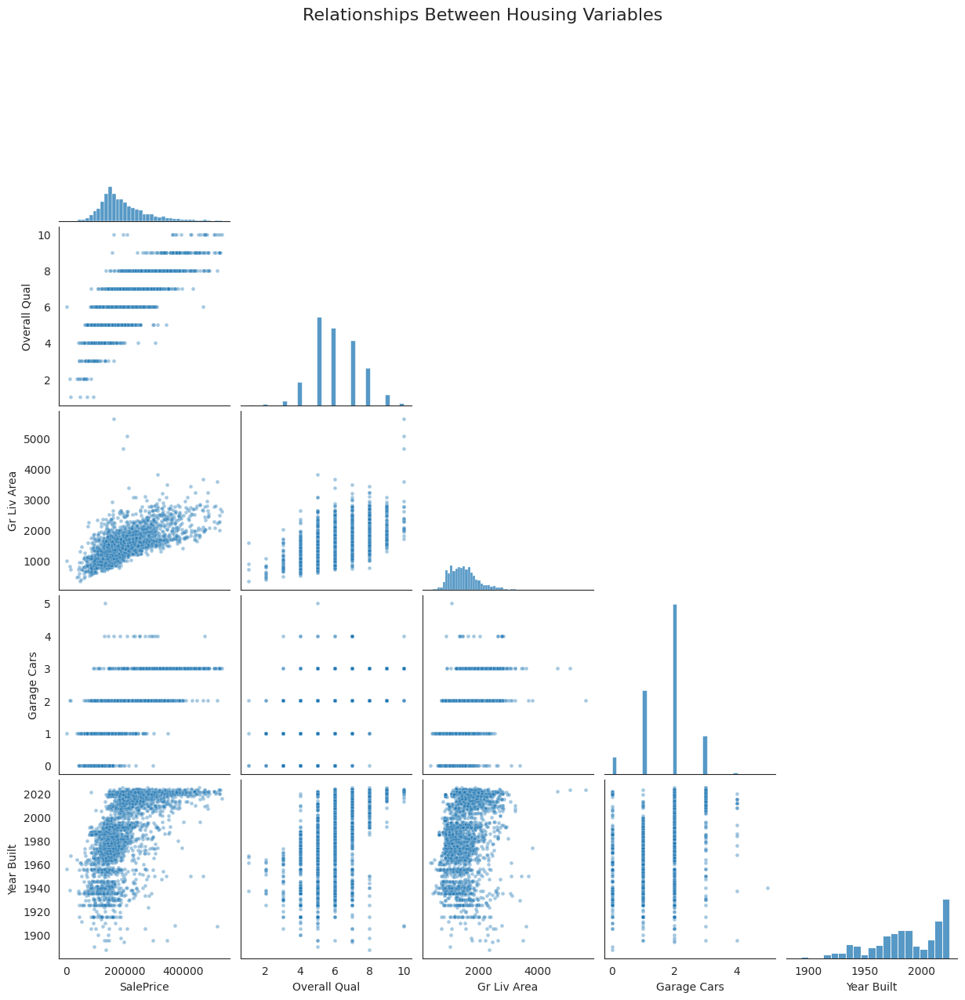

In [ ]:

import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Select variables from your housing dataset
pairplot_df = df[
    [
        "SalePrice",
        "Overall Qual",
        "Gr Liv Area",
        "Garage Cars",
        "Year Built"
    ]
].copy()

# Remove missing values for the plot
pairplot_df = pairplot_df.dropna()

# Limit extreme prices for visualization only
pairplot_df = pairplot_df[
    (pairplot_df["SalePrice"] > 0) &
    (pairplot_df["SalePrice"] <= 550000)
]

# Create pairplot
sns.pairplot(
    pairplot_df,
    diag_kind="hist",
    corner=True,
    plot_kws={"alpha": 0.4, "s": 12}
)

plt.suptitle(
    "Relationships Between Housing Variables",
    y=1.02,
    fontsize=16
)

plt.show()



AI Disclosure: I used Copilot and google to assist with creating some of the Python code for my bar chart. I reviewed the code, ran the analysis, and completed the interpretation of the results myself.

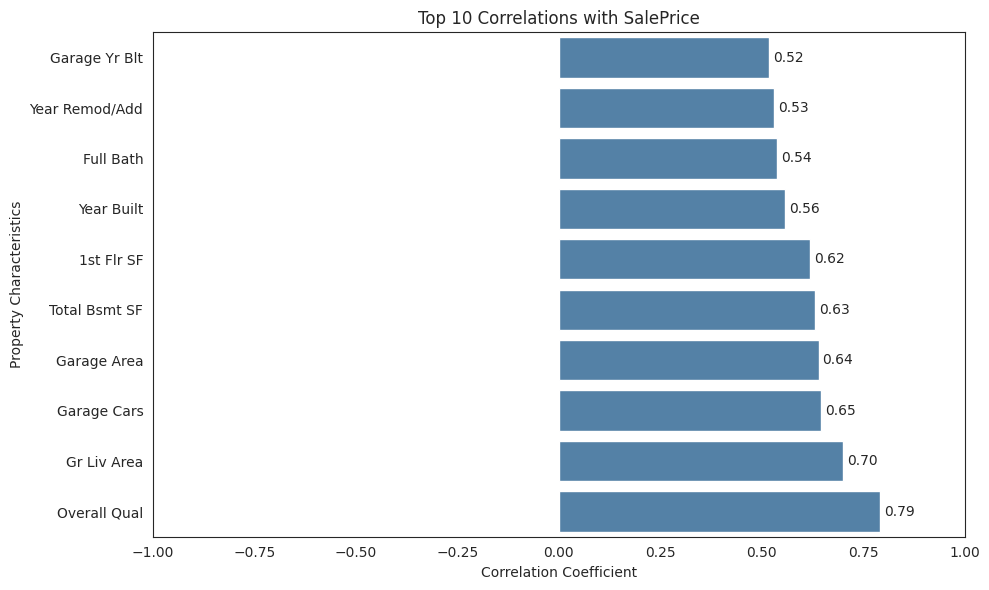

In [ ]:

# Top 10 correlations with SalePrice
# Use the existing outlier-filtered dataset

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical variables
numeric_df = df_filtered.select_dtypes(include="number")

# Calculate correlations with SalePrice
saleprice_corr = numeric_df.corr()["SalePrice"]

# Remove SalePrice itself
saleprice_corr = saleprice_corr.drop("SalePrice")

# Identify top 10 strongest correlations
top_corr = (
    saleprice_corr
    .abs()
    .sort_values(ascending=False)
    .head(10)
    .index
)

top_corr_values = saleprice_corr[top_corr].sort_values()

# Plot correlation chart
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=top_corr_values.values,
    y=top_corr_values.index,
    color="steelblue"
)

# Add correlation values
for i, value in enumerate(top_corr_values.values):
    ax.text(
        value + (0.01 if value >= 0 else -0.01),
        i,
        f"{value:.2f}",
        va="center",
        ha="left" if value >= 0 else "right"
    )

plt.title("Top 10 Correlations with SalePrice")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Property Characteristics")
plt.xlim(-1, 1)
plt.tight_layout()
plt.show()


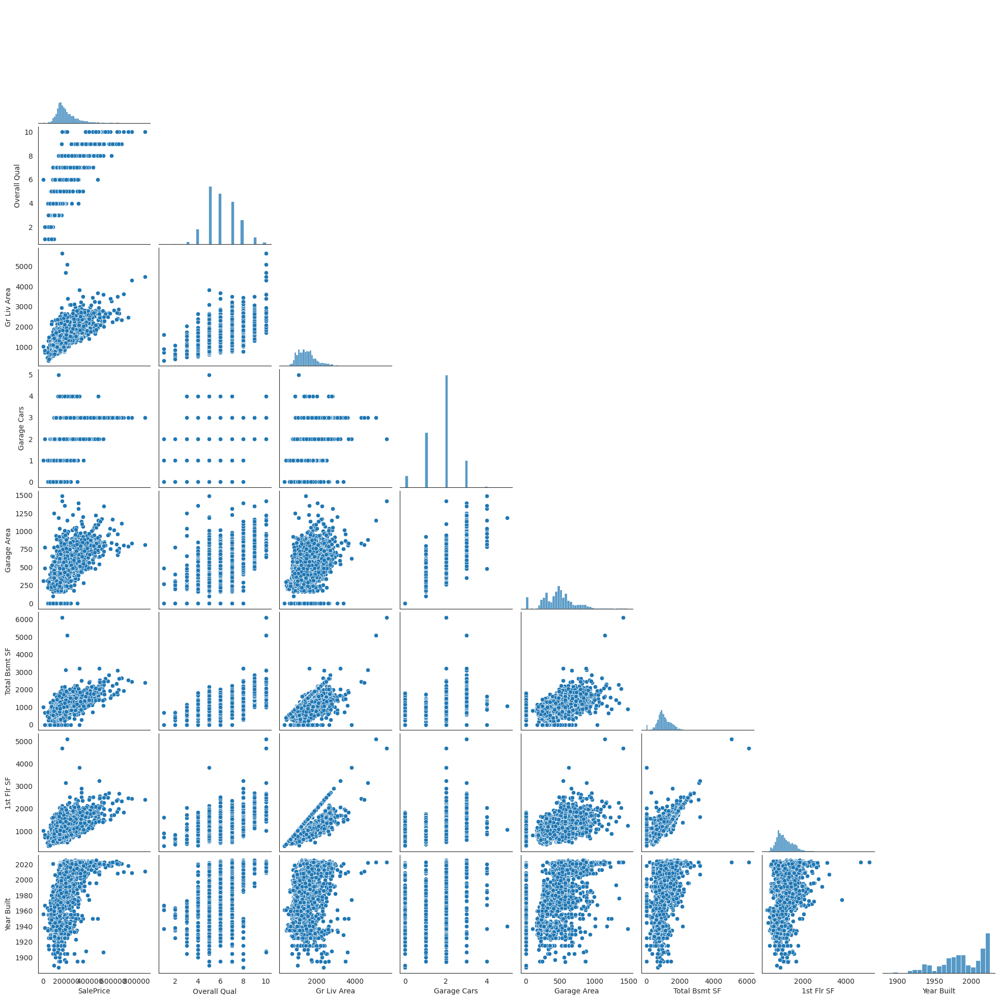

In [ ]:
# ==========================================
# PAIRPLOT - FILTERED DATASET
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

# Variables to include in the pairplot
pairplot_vars = [
    'SalePrice',
    'Overall Qual',
    'Gr Liv Area',
    'Garage Cars',
    'Garage Area',
    'Total Bsmt SF',
    '1st Flr SF',
    'Year Built'
]

# Use filtered dataset (outliers already removed)
pairplot_data = df_filtered[pairplot_vars].dropna().copy()

# Create pairplot
sns.pairplot(
    data=pairplot_data,
    diag_kind='hist',
    corner=True
)

plt.show()

## Visualizations with plotly

In [ ]:

import plotly.express as px

# Visualization only - do not change original df
df_box = df[
    (df["SalePrice"] > 0) &
    (df["SalePrice"] <= 550000)
].copy()

# Compare SalePrice across neighborhoods
fig = px.box(
    df_box,
    x="Neighborhood",
    y="SalePrice",
    title="Sale Price by Neighborhood",
    labels={
        "Neighborhood": "Neighborhood",
        "SalePrice": "Sale Price ($)"
    }
)

fig.update_layout(
    xaxis_tickangle=-45,
    height=600
)

fig.update_yaxes(
    tickprefix="$",
    tickformat=",.0f"
)

fig.show()


# Data Preparation

The data can be very "dirty" or not in the form we need it to be so we do considerable data wrangling.

This is the "Data Preparation" step in the CriSP-DM, but also called "Exploratory Data Analysis," or simply EDA.

In [ ]:
# Assess the shape before get dummies
df.shape

(2836, 82)

In [ ]:

# Clean missing values AFTER outlier filtering

columns = [
    'SalePrice',
    'Overall Qual',
    'Gr Liv Area',
    'Garage Cars',
    'Year Built',
    'Neighborhood',
    'Kitchen Qual'
]

print("Filtered rows before cleaning:", len(df_filtered))

df_clean = df_filtered[columns].dropna().copy()

print("Rows after cleaning:", len(df_clean))
print("Rows removed due to missing values:",
      len(df_filtered) - len(df_clean))


Filtered rows before cleaning: 2834
Rows after cleaning: 2833
Rows removed due to missing values: 1


In [ ]:

# Identify the row removed due to missing values

removed_rows = df_filtered[
    df_filtered[columns].isna().any(axis=1)
]

display(removed_rows[columns])

print("Missing values by column:")
print(removed_rows[columns].isna().sum())


,SalePrice,Overall Qual,Gr Liv Area,Garage Cars,Year Built,Neighborhood,Kitchen Qual
1836,"172,056.81",5.00,"1,828.00",NaN,"1,938.00",IDOTRR,Gd


Missing values by column:
SalePrice       0
Overall Qual    0
Gr Liv Area     0
Garage Cars     1
Year Built      0
Neighborhood    0
Kitchen Qual    0
dtype: int64


In [ ]:

# ==========================================
# MODEL 1: DATA PREPARATION
# ==========================================

import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error

# Select predictors
features = [
    'Overall Qual',
    'Gr Liv Area',
    'Garage Cars',
    'Year Built'
]

# Select relevant columns and remove missing values
model1_data = df_filtered[
    ['SalePrice'] + features
].dropna().copy()

# Define independent variables (X)
X1 = model1_data[features].astype(float)

# Define dependent variable (Y)
y1 = model1_data['SalePrice'].astype(float)

# Add intercept
X1_const = sm.add_constant(X1)

print("MODEL 1: DATA PREPARATION")
print("Observations:", len(model1_data))
print("Predictors:", features)
print("Missing values:", model1_data.isna().sum().sum())


MODEL 1: DATA PREPARATION
Observations: 2833
Predictors: ['Overall Qual', 'Gr Liv Area', 'Garage Cars', 'Year Built']
Missing values: 0


In [ ]:
# Load variable name to paste into get dummies below
df.dtypes

,0
PID,int64
MS SubClass,float64
MS Zoning,object
Lot Frontage,float64
Lot Area,float64
Street,object
Alley,object
Lot Shape,object
Land Contour,object
Utilities,object


In [ ]:
# Count missing values in each column
df.isnull().sum()[lambda x: x > 0]

,0
MS SubClass,1
MS Zoning,1
Lot Frontage,470
Lot Area,1
Street,1
Alley,2648
Lot Shape,1
Land Contour,1
Utilities,1
Lot Config,1


In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Get the independent variables from Model 5
X_vif = pd.DataFrame(
    model5.model.exog,
    columns=model5.model.exog_names
)

# Calculate VIF for each predictor
vif_results = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

# Remove the intercept from the displayed results
vif_results = vif_results[
    ~vif_results["Variable"].isin(["const", "Intercept"])
]

# Sort highest to lowest
vif_results = vif_results.sort_values(
    by="VIF",
    ascending=False
)

# Display results
print("Model 5 - Multicollinearity (VIF)")
display(vif_results.round(2))


Model 5 - Multicollinearity (VIF)


,Variable,VIF
20,Neighborhood_NAmes,15.63
25,Neighborhood_OldTown,11.23
10,Neighborhood_CollgCr,9.29
12,Neighborhood_Edwards,8.34
36,Kitchen Qual_TA,7.69
29,Neighborhood_Somerst,6.86
24,Neighborhood_NridgHt,6.76
27,Neighborhood_Sawyer,6.61
13,Neighborhood_Gilbert,6.40
34,Kitchen Qual_Gd,5.82


## nulls and nans

In [ ]:
df.isnull().sum()


,0
PID,0
MS SubClass,1
MS Zoning,1
Lot Frontage,470
Lot Area,1
Street,1
Alley,2648
Lot Shape,1
Land Contour,1
Utilities,1


AI Disclosure: I used Copilot and google to assist with creating some of the Python code for my bar chart. I reviewed the code, ran the analysis, and completed the interpretation of the results myself.

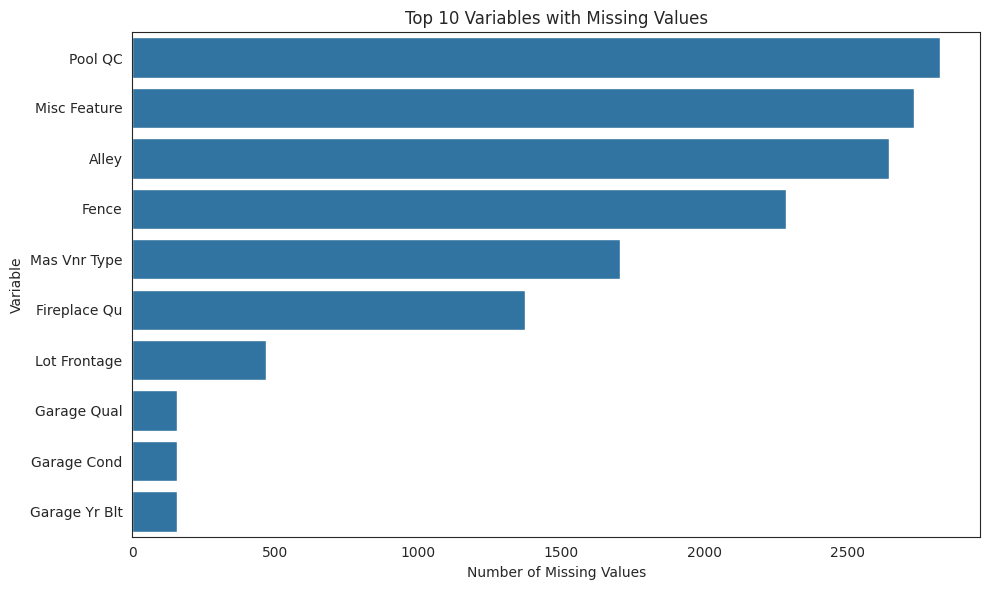

In [ ]:
# ==========================================
# MISSING VALUES ANALYSIS - FILTERED DATASET
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

# Count missing values
missing_values = df_filtered.isnull().sum()

# Keep only variables with missing values
missing_values = missing_values[missing_values > 0]

# Get top 10 variables with missing values
top_missing = missing_values.sort_values(
    ascending=False
).head(10)

# Create bar chart
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_missing.values,
    y=top_missing.index
)

plt.title("Top 10 Variables with Missing Values")
plt.xlabel("Number of Missing Values")
plt.ylabel("Variable")

plt.tight_layout()
plt.show()

*sklearn* and *statsmodels* will not model with categorical variables so all categorical variables MUST be encoded.

*sklearn* has its own encoding tools that transform variables into 0 representing  "False" and 1 representing "True". This is the better option than *pandas'* *get_dummies* that transforms all categorical variables into a boolean (i.e., "True" or "False"). A boolean is still a catgorical variable so not helpful for modeling with *sklearn* or *statsmodels*.

In [ ]:
# import sklearn for one hot encoding and test train split
# https://www.freecodecamp.org/news/how-to-build-and-train-linear-and-logistic-regression-ml-models-in-python/
import sklearn

AI Disclosure: I used Copilot and google to assist with creating some of the Python code for categoricak colums. I reviewed the code, ran the analysis, and completed the interpretation of the results myself.

In [ ]:
# Check the variable outputs
df.dtypes

,0
PID,int64
MS SubClass,float64
MS Zoning,object
Lot Frontage,float64
Lot Area,float64
Street,object
Alley,object
Lot Shape,object
Land Contour,object
Utilities,object


In [ ]:
# Create numerical dataset from filtered data
numeric_df = df_filtered.select_dtypes(
    include=['number']
).copy()

# Remove numerical identifiers and categorical codes
numeric_df = numeric_df.drop(
    columns=['PID', 'MS SubClass'],
    errors='ignore'
)

print("Numerical columns:", numeric_df.shape[1])
print("Observations:", numeric_df.shape[0])

Numerical columns: 36
Observations: 2834


In [ ]:

print("Dataset shape:", df.shape)

print("\nFirst 15 columns:")
print(df.columns[:15].tolist())

print("\nLast 20 columns:")
print(df.columns[-20:].tolist())

print("\nDuplicate column names:")
print(df.columns[df.columns.duplicated()].tolist())


Dataset shape: (2836, 82)

First 15 columns:
['PID', 'MS SubClass', 'MS Zoning', 'Lot Frontage', 'Lot Area', 'Street', 'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2']

Last 20 columns:
['Garage Area', 'Garage Qual', 'Garage Cond', 'Paved Drive', 'Wood Deck SF', 'Open Porch SF', 'Enclosed Porch', '3Ssn Porch', 'Screen Porch', 'Pool Area', 'Pool QC', 'Fence', 'Misc Feature', 'Misc Val', 'Mo Sold', 'Yr Sold', 'Sale Type', 'Sale Condition', 'SalePrice', 'Neighborhood_Grouped']

Duplicate column names:
[]


In [ ]:

# Check Neighborhood encoding without changing the dataset

neighborhood_cols = [
    col for col in df.columns
    if col.startswith("Neighborhood_")
]

print("Neighborhood dummy columns:")
print(neighborhood_cols)

print("\nNumber of dummy columns:", len(neighborhood_cols))

print("\nOriginal Neighborhood column exists:",
      "Neighborhood" in df.columns)


Neighborhood dummy columns:
['Neighborhood_Grouped']

Number of dummy columns: 1

Original Neighborhood column exists: True


In [ ]:

# Check predictors included in Model 5
if "model5" in globals():
    print("Model 5 predictors:")
    print(model5.model.exog_names)
else:
    print("Model 5 is not currently loaded.")


Model 5 predictors:
['const', 'Garage Cars', 'Year Built', 'Qual_Centered', 'LivArea_Centered', 'Qual_x_LivArea', 'Neighborhood_Blueste', 'Neighborhood_BrDale', 'Neighborhood_BrkSide', 'Neighborhood_ClearCr', 'Neighborhood_CollgCr', 'Neighborhood_Crawfor', 'Neighborhood_Edwards', 'Neighborhood_Gilbert', 'Neighborhood_Greens', 'Neighborhood_GrnHill', 'Neighborhood_IDOTRR', 'Neighborhood_Landmrk', 'Neighborhood_MeadowV', 'Neighborhood_Mitchel', 'Neighborhood_NAmes', 'Neighborhood_NPkVill', 'Neighborhood_NWAmes', 'Neighborhood_NoRidge', 'Neighborhood_NridgHt', 'Neighborhood_OldTown', 'Neighborhood_SWISU', 'Neighborhood_Sawyer', 'Neighborhood_SawyerW', 'Neighborhood_Somerst', 'Neighborhood_StoneBr', 'Neighborhood_Timber', 'Neighborhood_Veenker', 'Kitchen Qual_Fa', 'Kitchen Qual_Gd', 'Kitchen Qual_Po', 'Kitchen Qual_TA']


In [ ]:

import pandas as pd
import numpy as np
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Get the independent variables from Model 5
X_vif = pd.DataFrame(
    model5.model.exog,
    columns=model5.model.exog_names
)

# Calculate VIF for each predictor
vif_results = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

# Remove the intercept from the displayed results
vif_results = vif_results[
    ~vif_results["Variable"].isin(["const", "Intercept"])
]

# Sort highest to lowest
vif_results = vif_results.sort_values(
    by="VIF",
    ascending=False
)

# Display results
print("Model 5 - Multicollinearity (VIF)")
display(vif_results.round(2))


Model 5 - Multicollinearity (VIF)


,Variable,VIF
20,Neighborhood_NAmes,15.63
25,Neighborhood_OldTown,11.23
10,Neighborhood_CollgCr,9.29
12,Neighborhood_Edwards,8.34
36,Kitchen Qual_TA,7.69
29,Neighborhood_Somerst,6.86
24,Neighborhood_NridgHt,6.76
27,Neighborhood_Sawyer,6.61
13,Neighborhood_Gilbert,6.40
34,Kitchen Qual_Gd,5.82


# Modeling

Most examples for modeling show how the data is **randomly** split into a training set (roughly 80% of the full dataset) and a testing set (the remaining 20% of the dataset).

We do this to train the model on the majority of the data and use a smaller amount of the data to test the results.

**NOTE:** Splitting data happens AFTER all data wrangling and is part of the *modeling* step in the CrISP-DM (not *data prepartion* step).

In [ ]:
# load test train split python package
from sklearn.model_selection import train_test_split

In [ ]:
# ==========================================
# STRATIFIED SAMPLING
# ==========================================

# X = all predictors except SalePrice
X = df_filtered.drop("SalePrice", axis='columns')

# y = target variable
y = df_filtered["SalePrice"]

print(y.shape)
print(X.shape)

(2834,)
(2834, 80)


In [ ]:
y.dtypes

dtype('float64')

In [ ]:
X.dtypes

,0
PID,int64
MS SubClass,float64
MS Zoning,object
Lot Frontage,float64
Lot Area,float64
Street,object
Alley,object
Lot Shape,object
Land Contour,object
Utilities,object


In [ ]:
# For analysis on people, we would typcially want a stratified sample based on
#  gender but that is a categorical variable and not in this example.
# stratVar=X["SEX_string"] #define the variable used for the stratified sample
# a stratified sample ensures an equal representation of a particular category (or group) is in both the training and testin dataframes
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=.2, train_size=.8, random_state=7, shuffle=True)#, stratify=stratVar)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

#read more
# k fold stratification
#https://scikit-learn.org/stable/modules/cross_validation.html#stratification

(2267, 80)
(567, 80)
(2267,)
(567,)


In [ ]:
# analyze the y data (the target variable) used in the training
y_train.describe()

,SalePrice
count,"2,267.00"
mean,"201,000.14"
std,"91,437.46"
min,500.00
25%,"142,887.48"
50%,"178,488.73"
75%,"237,770.06"
max,"876,575.71"


In [ ]:
# analyze the y data (the target variable) used in the testing
y_test.describe()

,SalePrice
count,567.00
mean,"190,867.93"
std,"78,435.58"
min,"13,559.33"
25%,"138,393.17"
50%,"174,308.98"
75%,"228,917.02"
max,"510,445.53"


## Modeling: statsmodels.api

In [ ]:
# Load Library
# https://www.statsmodels.org/stable/api.html#regression
import statsmodels.api as sm


In [ ]:
# If X_train has bool values, they need to be converted to numerical values of 0 or 1 for Statsmodels.api
# If string or object variables are in the data frame, then they also need to be encoded
# Convert boolean columns to numerical (0 and 1)
# prompt: build a function for a df to identify bool variables and transform them to int

def transform_bool_to_int(df):
    """
    Identifies boolean variables in a Pandas DataFrame and transforms them to integers (1 for True, 0 for False).
    Args:
        df: The input DataFrame.
    Returns:
        A DataFrame with boolean columns converted to integer type.
    """
    for col in df.columns:
        if pd.api.types.is_bool_dtype(df[col]):
            df[col] = df[col].astype(int)
    return df


In [ ]:
# Select variables for regression

reg_data = df_filtered[
    [
        "SalePrice",
        "Overall Qual",
        "Lot Area",
        "Year Built",
        "Total Bsmt SF"
    ]
].copy()
print("record count before drop:", len(reg_data))
reg_data = reg_data.dropna()

print("Regression data created.")
print("Observations used:       ", len(reg_data))
print("Variables:", reg_data.columns.tolist())

record count before drop: 2834
Regression data created.
Observations used:        2833
Variables: ['SalePrice', 'Overall Qual', 'Lot Area', 'Year Built', 'Total Bsmt SF']


In [ ]:
# Define independent and dependent variables

X = reg_data[
    [
        "Overall Qual",
        "Lot Area",
        "Year Built",
        "Total Bsmt SF"
    ]
]

y = reg_data["SalePrice"]

print("Predictors:", X.columns.tolist())
print("X shape:", X.shape)
print("y shape:", y.shape)

Predictors: ['Overall Qual', 'Lot Area', 'Year Built', 'Total Bsmt SF']
X shape: (2833, 4)
y shape: (2833,)


## Modeling sklearn

Used Gemini for guidance for the models

# week 6

Mode1: 4 numeric variables

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 2266
Testing observations: 567


model 1

In [ ]:

# ==========================================
# MODEL 1: OLS REGRESSION
# ==========================================

import statsmodels.api as sm

# Select Model 1 predictors
features = [
    'Overall Qual',
    'Gr Liv Area',
    'Garage Cars',
    'Year Built'
]

# Prepare modeling data
model1_data = df_filtered[
    ['SalePrice'] + features
].dropna().copy()

# Define independent and dependent variables
X1 = model1_data[features].astype(float)
y1 = model1_data['SalePrice'].astype(float)

# Add intercept
X1_const = sm.add_constant(X1)

# Fit multiple linear regression
model1_full = sm.OLS(y1, X1_const).fit()

# Display regression results
print(model1_full.summary())


                            OLS Regression Results                            
Dep. Variable:              SalePrice   R-squared:                       0.752
Model:                            OLS   Adj. R-squared:                  0.751
Method:                 Least Squares   F-statistic:                     2141.
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        03:17:41   Log-Likelihood:                -34334.
No. Observations:                2833   AIC:                         6.868e+04
Df Residuals:                    2828   BIC:                         6.871e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const        -9.046e+05   7.08e+04    -12.771   

In [ ]:

# ==========================================
# MODEL 1: PERFORMANCE EVALUATION
# ==========================================

import numpy as np
from sklearn.metrics import mean_squared_error

# Generate predictions
y_pred1 = model1_full.predict(X1_const)

# Calculate in-sample RMSE
rmse1 = np.sqrt(
    mean_squared_error(y1, y_pred1)
)

# Display performance metrics
print("MODEL 1: PERFORMANCE SUMMARY")
print("------------------------------")

print(f"Observations: {int(model1_full.nobs):,}")
print(f"R²: {model1_full.rsquared:.4f}")
print(f"Adjusted R²: {model1_full.rsquared_adj:.4f}")
print(f"F-statistic: {model1_full.fvalue:.2f}")
print(f"Overall p-value: {model1_full.f_pvalue:.6g}")
print(f"In-Sample RMSE: ${rmse1:,.2f}")


MODEL 1: PERFORMANCE SUMMARY
------------------------------
Observations: 2,833
R²: 0.7518
Adjusted R²: 0.7514
F-statistic: 2141.30
Overall p-value: 0
In-Sample RMSE: $44,374.10


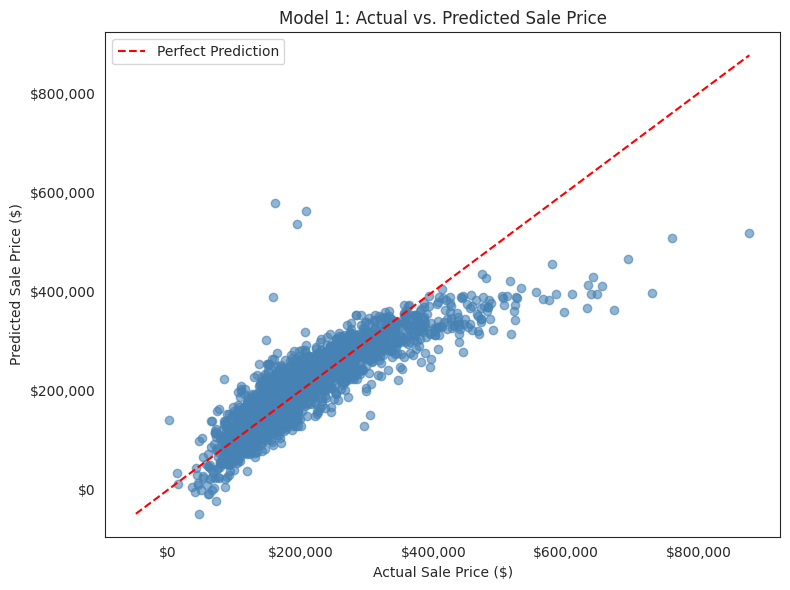

Model 1 actual vs. predicted plot created.


In [ ]:
# ==========================================
# MODEL 1: ACTUAL VS. PREDICTED SALEPRICE
# ==========================================

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Generate predictions from Model 1
y_pred1 = model1_full.predict(X1_const)

# Create scatter plot
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    y1,
    y_pred1,
    color="steelblue",
    alpha=0.6
)

# Calculate reference line limits
minimum = min(y1.min(), y_pred1.min())
maximum = max(y1.max(), y_pred1.max())

# Perfect prediction reference line
ax.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    color="red",
    label="Perfect Prediction"
)

# Labels and title
ax.set_xlabel("Actual Sale Price ($)")
ax.set_ylabel("Predicted Sale Price ($)")
ax.set_title("Model 1: Actual vs. Predicted Sale Price")

# Format axes with dollar signs and commas
ax.xaxis.set_major_formatter(
    mtick.StrMethodFormatter('${x:,.0f}')
)
ax.yaxis.set_major_formatter(
    mtick.StrMethodFormatter('${x:,.0f}')
)

# Remove gridlines
ax.grid(False)

# White background
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

ax.legend()
plt.tight_layout()
plt.show()

print("Model 1 actual vs. predicted plot created.")

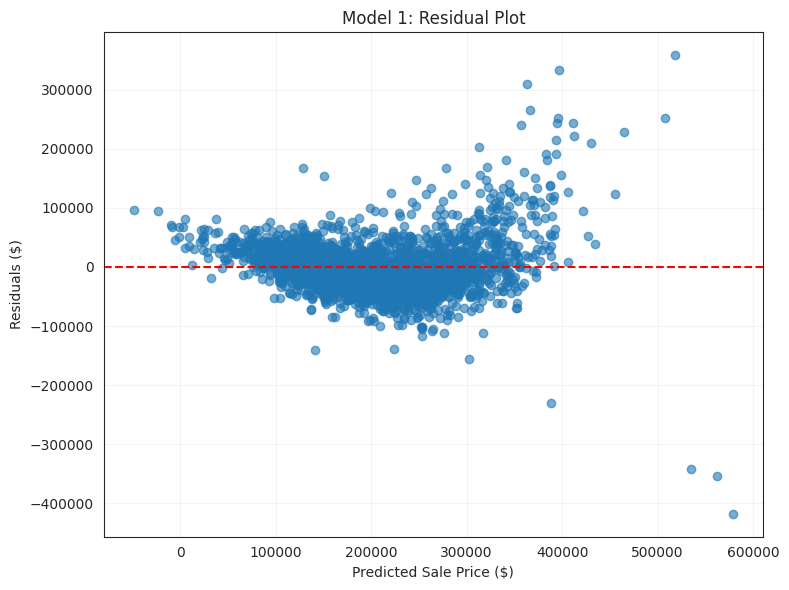

Model 1 residual plot created.
Mean residual: 0.0


In [ ]:

# ==========================================
# MODEL 1: RESIDUAL ANALYSIS
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

# Generate predictions
y_pred1 = model1_full.predict(X1_const)

# Calculate residuals
residuals1 = y1 - y_pred1

# Create residual plot
plt.figure(figsize=(8, 6))

plt.scatter(
    y_pred1,
    residuals1,
    alpha=0.6
)

# Add horizontal reference line at zero
plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

# Labels and title
plt.xlabel("Predicted Sale Price ($)")
plt.ylabel("Residuals ($)")
plt.title("Model 1: Residual Plot")

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Display residual summary
print("Model 1 residual plot created.")
print("Mean residual:", round(residuals1.mean(), 2))


## model 2: 6 numeric variables

Model 2 improved performance, explaining 77.9% of the variation in SalePrice. All six predictors were statistically significant
p < .05

In [ ]:
# MODEL 2 - remove missing values first

model2_data = df_filtered[
    ['SalePrice',
     'Overall Qual',
     'Lot Area',
     'Year Built',
     'Total Bsmt SF',
     'Gr Liv Area',
     'Garage Cars']
].dropna()

y2 = model2_data['SalePrice']

X2 = model2_data[
    ['Overall Qual',
     'Lot Area',
     'Year Built',
     'Total Bsmt SF',
     'Gr Liv Area',
     'Garage Cars']
]

X2 = sm.add_constant(X2)

model2 = sm.OLS(y2, X2).fit()

print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:              SalePrice   R-squared:                       0.779
Model:                            OLS   Adj. R-squared:                  0.778
Method:                 Least Squares   F-statistic:                     1657.
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        03:17:42   Log-Likelihood:                -34159.
No. Observations:                2832   AIC:                         6.833e+04
Df Residuals:                    2825   BIC:                         6.837e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const         -8.006e+05   6.75e+04    -11.855

In [ ]:
import numpy as np
from sklearn.metrics import mean_squared_error

pred2 = model2.predict(X2)

rmse2 = np.sqrt(mean_squared_error(y2, pred2))

print(f"Model 2 R-Squared: {model2.rsquared:.4f}")
print(f"Model 2 Adjusted R-Squared: {model2.rsquared_adj:.4f}")
print(f"Model 2 RMSE: ${rmse2:,.4f}")
print(f"Model 2 F-Statistic: {model2.fvalue:.4f}")
print(f"Model 2 P-Value: {model2.f_pvalue:.4f}")

Model 2 R-Squared: 0.7787
Model 2 Adjusted R-Squared: 0.7782
Model 2 RMSE: $41,894.7312
Model 2 F-Statistic: 1656.8665
Model 2 P-Value: 0.0000


Week 7

In [ ]:

# ==========================================
# MODEL 3: NEIGHBORHOOD REGRESSION
# ==========================================

import pandas as pd
import numpy as np
import statsmodels.api as sm

# 1. Select variables from filtered dataset
model3_data = df_filtered[
    [
        'SalePrice',
        'Overall Qual',
        'Gr Liv Area',
        'Garage Cars',
        'Neighborhood'
    ]
].dropna().copy()

# 2. Create neighborhood dummy variables
# NAmes is the reference category
neighborhood_dummies = pd.get_dummies(
    model3_data['Neighborhood'],
    prefix='Neighborhood',
    dtype=int
)

# Remove reference category
neighborhood_dummies = neighborhood_dummies.drop(
    columns=['Neighborhood_NAmes']
)

# 3. Define numerical predictors
X3_numeric = model3_data[
    ['Overall Qual', 'Gr Liv Area', 'Garage Cars']
].astype(float)

# 4. Combine predictors and dummy variables
X3 = pd.concat(
    [X3_numeric, neighborhood_dummies],
    axis=1
)

# 5. Define dependent variable
y3 = model3_data['SalePrice'].astype(float)

# 6. Add intercept
X3_const = sm.add_constant(X3)

# 7. Fit regression
model3 = sm.OLS(y3, X3_const).fit()

# 8. Display results
print(model3.summary())

# 9. Performance summary
rmse3 = np.sqrt(np.mean(model3.resid ** 2))

print("\nMODEL 3: PERFORMANCE SUMMARY")
print("-----------------------------")
print(f"Observations: {int(model3.nobs):,}")
print(f"R²: {model3.rsquared:.4f}")
print(f"Adjusted R²: {model3.rsquared_adj:.4f}")
print(f"F-statistic: {model3.fvalue:.2f}")
print(f"Overall p-value: {model3.f_pvalue:.6g}")
print(f"In-Sample RMSE: ${rmse3:,.2f}")


                            OLS Regression Results                            
Dep. Variable:              SalePrice   R-squared:                       0.794
Model:                            OLS   Adj. R-squared:                  0.792
Method:                 Least Squares   F-statistic:                     360.1
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        03:17:42   Log-Likelihood:                -34070.
No. Observations:                2833   AIC:                         6.820e+04
Df Residuals:                    2802   BIC:                         6.839e+04
Df Model:                          30                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                 -5.66e+04 

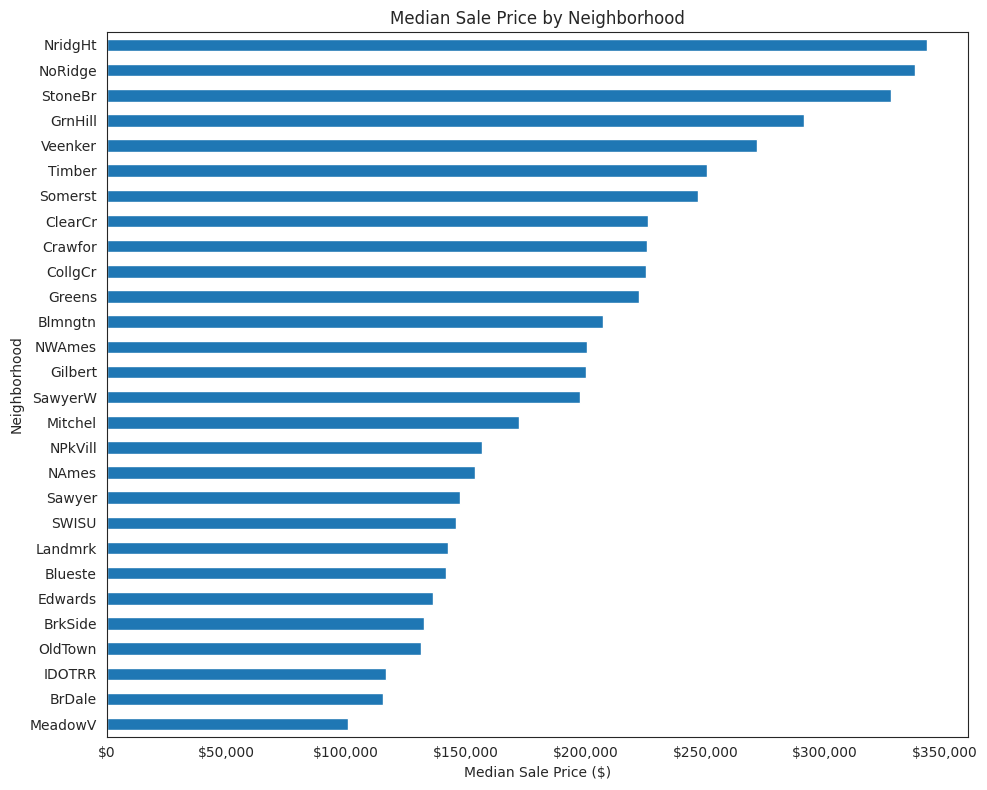

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Median SalePrice by Neighborhood
neighborhood_price = (
    df_filtered.groupby("Neighborhood")["SalePrice"]
    .median()
    .sort_values()
)

plt.figure(figsize=(10, 8))

neighborhood_price.plot(kind="barh")

plt.title("Median Sale Price by Neighborhood")
plt.xlabel("Median Sale Price ($)")
plt.ylabel("Neighborhood")

# Add $ and commas to the x-axis
plt.gca().xaxis.set_major_formatter(
    mtick.StrMethodFormatter('${x:,.0f}')
)

plt.tight_layout()
plt.show()

/tmp/ipykernel_4583/2068438543.py:18: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



<Figure size 1500x700 with 0 Axes>

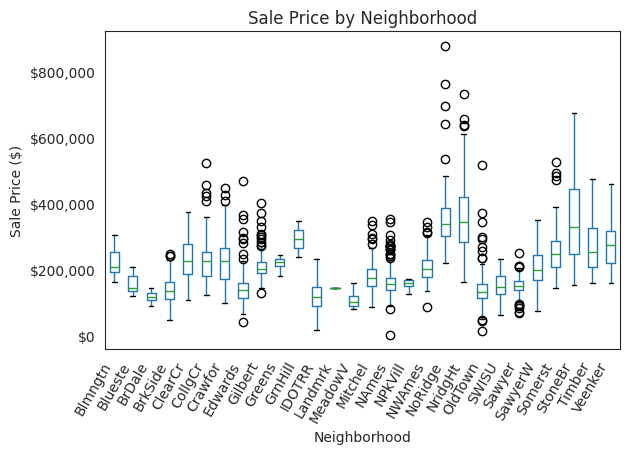

SalePrice by Neighborhood box plot created.


In [ ]:
# Model 3 Visual: SalePrice by Neighborhood

plt.figure(figsize=(15, 7))

df_filtered.boxplot(
    column="SalePrice",
    by="Neighborhood",
    grid=False
)

plt.title("Sale Price by Neighborhood")
plt.suptitle("")
plt.xlabel("Neighborhood")
plt.ylabel("Sale Price ($)")

# Add dollar signs to Y-axis
ax = plt.gca()
ax.set_yticklabels(
    [f"${x:,.0f}" for x in ax.get_yticks()]
)

plt.xticks(rotation=60, ha="right")

plt.tight_layout()
plt.show()

print("SalePrice by Neighborhood box plot created.")

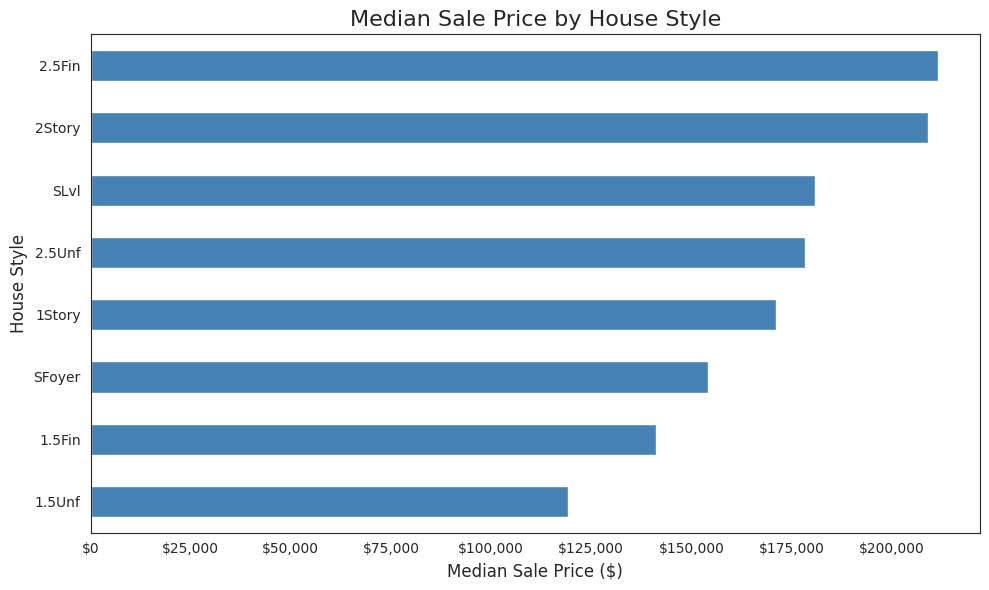

In [ ]:
# ==========================================
# MEDIAN SALEPRICE BY HOUSE STYLE - NO GRID
# ==========================================

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Median SalePrice by House Style
house_style_price = (
    df_filtered.groupby("House Style")["SalePrice"]
    .median()
    .sort_values()
)

# Create figure
fig, ax = plt.subplots(figsize=(10, 6))

house_style_price.plot(
    kind="barh",
    ax=ax,
    color="steelblue"
)

# Titles and labels
ax.set_title("Median Sale Price by House Style", fontsize=16)
ax.set_xlabel("Median Sale Price ($)", fontsize=12)
ax.set_ylabel("House Style", fontsize=12)

# Format dollar amounts
ax.xaxis.set_major_formatter(
    mtick.StrMethodFormatter('${x:,.0f}')
)

# Remove gridlines
ax.grid(False)

# White background
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

plt.tight_layout()
plt.show()

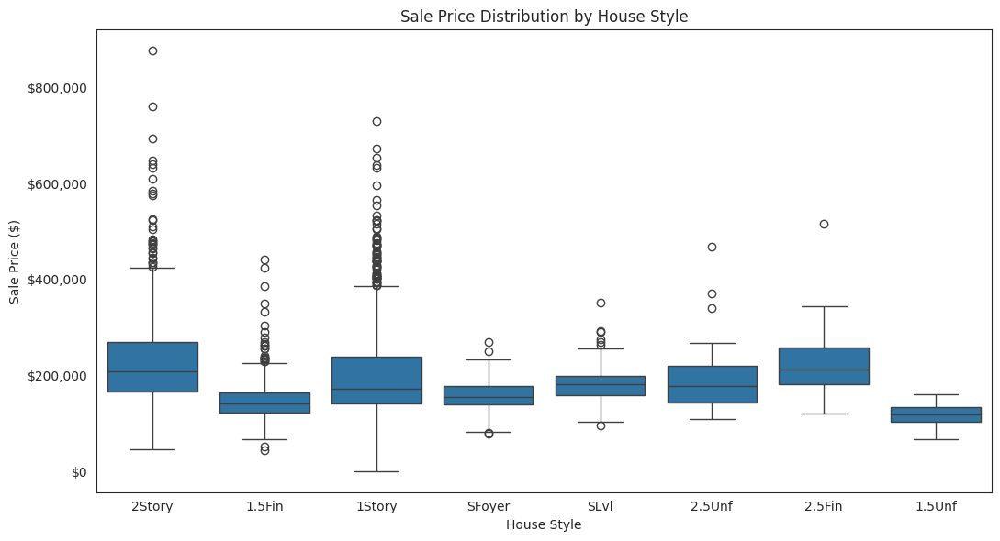

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mtick

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df_filtered,
    x="House Style",
    y="SalePrice"
)

plt.title("Sale Price Distribution by House Style")
plt.xlabel("House Style")
plt.ylabel("Sale Price ($)")

# Dollar formatting
plt.gca().yaxis.set_major_formatter(
    mtick.StrMethodFormatter('${x:,.0f}')
)

plt.tight_layout()
plt.show()

In [ ]:
# -----------------------------
# MODEL 4
# Add House Style
# -----------------------------

# Select Model 4 variables
model4_data = df_filtered[
    [
        "SalePrice",
        "Overall Qual",
        "Gr Liv Area",
        "Garage Cars",
        "House Style"
    ]
].dropna()

# Dummy encode House Style
model4_data = pd.get_dummies(
    model4_data,
    columns=["House Style"],
    drop_first=True,
    dtype=int
)

# Dependent variable
y4 = model4_data["SalePrice"]

# Independent variables
X4 = model4_data.drop(columns=["SalePrice"])

# Add constant
X4 = sm.add_constant(X4)

# Run Model 4
model4 = sm.OLS(y4, X4).fit()

# Show results
print(model4.summary())

                            OLS Regression Results                            
Dep. Variable:              SalePrice   R-squared:                       0.768
Model:                            OLS   Adj. R-squared:                  0.767
Method:                 Least Squares   F-statistic:                     932.3
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        03:17:43   Log-Likelihood:                -34241.
No. Observations:                2833   AIC:                         6.850e+04
Df Residuals:                    2822   BIC:                         6.857e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const              -1.465e+05   4298

/tmp/ipykernel_4583/3042016110.py:18: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



<Figure size 1000x600 with 0 Axes>

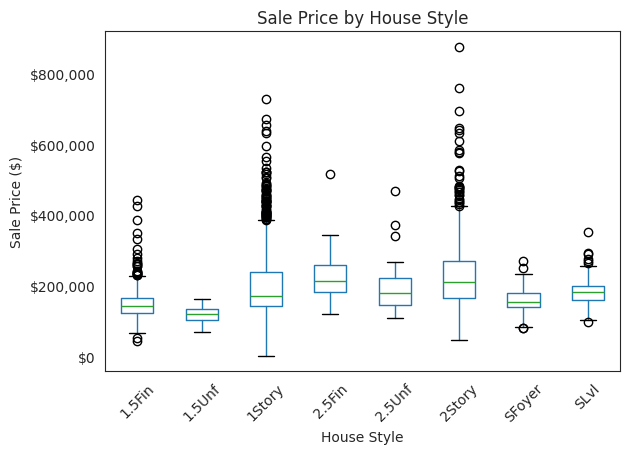

SalePrice by House Style box plot created.


In [ ]:
# Model 4 Visual: SalePrice by House Style

plt.figure(figsize=(10, 6))

df_filtered.boxplot(
    column="SalePrice",
    by="House Style",
    grid=False
)

plt.title("Sale Price by House Style")
plt.suptitle("")
plt.xlabel("House Style")
plt.ylabel("Sale Price ($)")

# Add dollar formatting
ax = plt.gca()
ax.set_yticklabels(
    [f"${x:,.0f}" for x in ax.get_yticks()]
)

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

print("SalePrice by House Style box plot created.")

In [ ]:
# -----------------------------
# MODEL COMPARISON TABLE
# -----------------------------

comparison = pd.DataFrame({
    "Model": [
        "Week 6 Model 1",
        "Week 6 Model 2",
        "Model 3",
        "Model 4"
    ],

    "Categorical Variable": [
        "None",
        "None",
        "Neighborhood",
        "House Style"
    ],

    "R²": [
        model1_full.rsquared,
        model2.rsquared,
        model3.rsquared,
        model4.rsquared
    ],

    "Adjusted R²": [
        model1_full.rsquared_adj,
        model2.rsquared_adj,
        model3.rsquared_adj,
        model4.rsquared_adj
    ]
})

# Format R² as percentages
comparison["R²"] = comparison["R²"].apply(
    lambda x: f"{x * 100:.1f}%"
)

# Format Adjusted R² as percentages
comparison["Adjusted R²"] = comparison["Adjusted R²"].apply(
    lambda x: "N/A" if pd.isna(x) else f"{x * 100:.1f}%"
)

# Display table
comparison

,Model,Categorical Variable,R²,Adjusted R²
0,Week 6 Model 1,None,75.2%,75.1%
1,Week 6 Model 2,None,77.9%,77.8%
2,Model 3,Neighborhood,79.4%,79.2%
3,Model 4,House Style,76.8%,76.7%


WEEK 8



In [ ]:
# MODEL 5: Advanced Multiple Linear Regression
# With Dummy Encoding and Interaction Effects

import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error

# Step 1: Select variables from filtered dataset
model5_data = df_filtered[
    [
        "SalePrice",
        "Overall Qual",
        "Gr Liv Area",
        "Garage Cars",
        "Neighborhood",

        "Year Built"
    ]
].dropna().copy()

# Step 2: Center numerical variables
# Centering makes interaction coefficients easier to interpret

model5_data["Qual_Centered"] = (
    model5_data["Overall Qual"] -
    model5_data["Overall Qual"].mean()
)

model5_data["LivArea_Centered"] = (
    model5_data["Gr Liv Area"] -
    model5_data["Gr Liv Area"].mean()
)

# Step 3: Create interaction term
# Test whether living area's relationship with
# SalePrice depends on overall quality

model5_data["Qual_x_LivArea"] = (
    model5_data["Qual_Centered"] *
    model5_data["LivArea_Centered"]
)

# Step 4: Dummy encode categorical variables
model5_data = pd.get_dummies(
    model5_data,
    columns=["Neighborhood"],
    drop_first=True,
    dtype=int
)

# Step 5: Define dependent variable
y5 = model5_data["SalePrice"]

# Step 6: Define independent variables
# Use centered versions instead of original variables
X5 = model5_data.drop(
    columns=[
        "SalePrice",
        "Overall Qual",
        "Gr Liv Area"
    ]
)

# Step 7: Add constant
X5 = sm.add_constant(X5)

# Step 8: Fit Model 5
model5 = sm.OLS(y5, X5).fit()

# Step 9: Generate predictions
pred5 = model5.predict(X5)

# Step 10: Calculate RMSE
rmse5 = np.sqrt(
    mean_squared_error(y5, pred5)
)

# Step 11: Display regression results
print(model5.summary())

# Step 12: Display model performance
print("\nMODEL 5 PERFORMANCE")

print(f"R-squared: {model5.rsquared:.4f}")
print(f"Adjusted R-squared: {model5.rsquared_adj:.4f}")
print(f"RMSE: ${rmse5:,.2f}")
print(f"F-statistic: {model5.fvalue:.4f}")
print(f"P-value: {model5.f_pvalue:.4g}")
print(f"Observations: {int(model5.nobs)}")

# Step 13: Evaluate interaction effect
print("\nINTERACTION EFFECT")

print(
    "Interaction Coefficient:",
    f"{model5.params['Qual_x_LivArea']:.4f}"
)

print(
    "Interaction P-value:",
    f"{model5.pvalues['Qual_x_LivArea']:.4g}"
)

# Step 14: Identify statistically significant predictors
significant = model5.pvalues[
    (model5.pvalues < 0.05) &
    (model5.pvalues.index != "const")
]

print("\nSTATISTICALLY SIGNIFICANT PREDICTORS")
print(significant.round(4))

                            OLS Regression Results                            
Dep. Variable:              SalePrice   R-squared:                       0.810
Model:                            OLS   Adj. R-squared:                  0.808
Method:                 Least Squares   F-statistic:                     372.2
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        03:19:17   Log-Likelihood:                -33958.
No. Observations:                2833   AIC:                         6.798e+04
Df Residuals:                    2800   BIC:                         6.818e+04
Df Model:                          32                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                -5.478e+05 

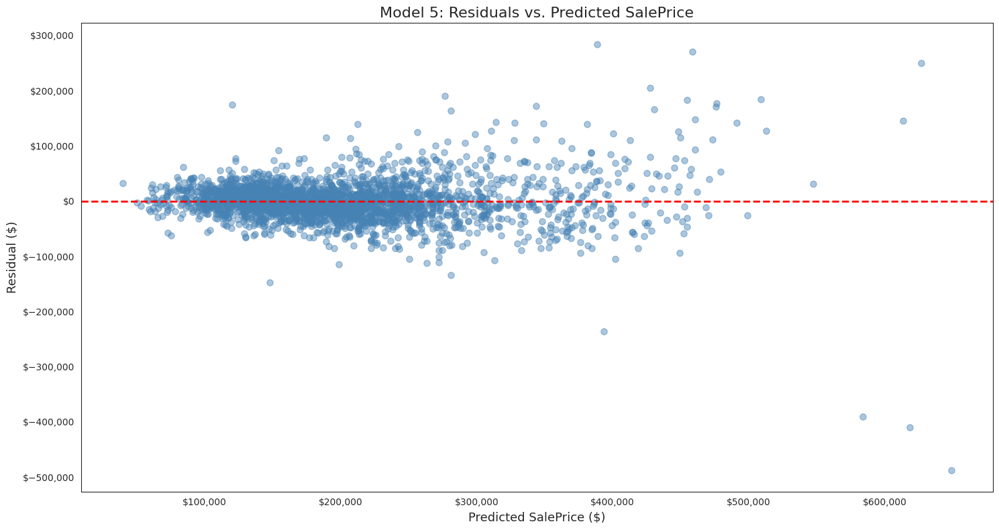

In [ ]:
# ==========================================
# MODEL 5: RESIDUAL ANALYSIS
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Use fitted Model 5 results
predicted5 = model5.fittedvalues
residuals5 = model5.resid

# Create plot
plt.figure(figsize=(15, 8), facecolor='white')

plt.scatter(
    predicted5,
    residuals5,
    color='steelblue',
    alpha=0.45,
    s=45
)

# Zero residual reference line
plt.axhline(
    y=0,
    color='red',
    linestyle='--',
    linewidth=2
)

# Labels and title
plt.title(
    "Model 5: Residuals vs. Predicted SalePrice",
    fontsize=16
)
plt.xlabel("Predicted SalePrice ($)", fontsize=13)
plt.ylabel("Residual ($)", fontsize=13)

# Format axes as dollars
ax = plt.gca()

ax.xaxis.set_major_formatter(
    StrMethodFormatter('${x:,.0f}')
)

ax.yaxis.set_major_formatter(
    StrMethodFormatter('${x:,.0f}')
)

# White background without gridlines
ax.set_facecolor('white')
ax.grid(False)

plt.tight_layout()
plt.show()

In [ ]:

# ==========================================
# COMPARISON OF ALL FIVE REGRESSION MODELS
# ==========================================

import pandas as pd
import numpy as np

# Use the correct fitted model names
models = {
    "Model 1": model1_full,
    "Model 2": model2,
    "Model 3": model3,
    "Model 4": model4,
    "Model 5": model5
}

# Create comparison table
comparison = pd.DataFrame([
    {
        "Model": name,
        "R²": f"{result.rsquared * 100:.1f}%",
        "Adjusted R²": f"{result.rsquared_adj * 100:.1f}%",
        "RMSE ($)": round(
            np.sqrt(np.mean(result.resid ** 2)), 2
        ),
        "Predictors": int(result.df_model),
        "Observations": int(result.nobs)
    }
    for name, result in models.items()
])

# Display comparison table
display(comparison)


,Model,R²,Adjusted R²,RMSE ($),Predictors,Observations
0,Model 1,75.2%,75.1%,"44,374.10",4,2833
1,Model 2,77.9%,77.8%,"41,894.73",6,2832
2,Model 3,79.4%,79.2%,"40,419.67",30,2833
3,Model 4,76.8%,76.7%,"42,932.87",10,2833
4,Model 5,82.4%,82.1%,"37,395.86",36,2833


# Assessment

## Shapley Values

In [ ]:
# Import the assessment Python package
import shap


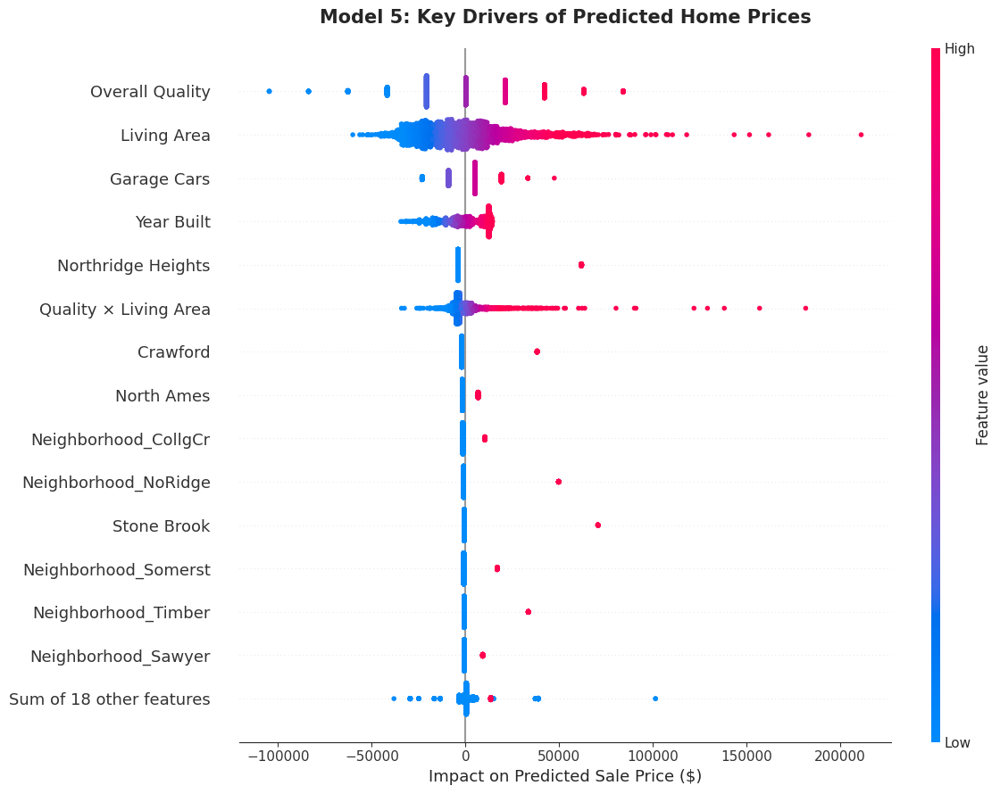

Model 5 SHAP analysis completed.


In [ ]:

# ==========================================
# MODEL 5: SHAP ANALYSIS
# ==========================================

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Use the exact predictors from Model 5
X_shap = X5.copy().astype(float)

# 2. Remove intercept from SHAP features
X_shap = X_shap.drop(
    columns=['const'],
    errors='ignore'
)

# 3. Extract Model 5 coefficients
coefficients = model5.params.reindex(
    X_shap.columns
).to_numpy()

# Check coefficient alignment
assert not np.isnan(coefficients).any(), \
    "Model 5 coefficients do not match X_shap columns."

# 4. Create SHAP explainer
# The intercept is excluded because SHAP
# explains differences from the baseline prediction.
explainer = shap.LinearExplainer(
    (coefficients, 0.0),
    X_shap
)

# 5. Calculate SHAP values
shap_values = explainer(X_shap)

# 6. Rename features for presentation
rename_features = {
    'Qual_Centered': 'Overall Quality',
    'LivArea_Centered': 'Living Area',
    'Qual_x_LivArea': 'Quality × Living Area',
    'Garage Cars': 'Garage Cars',
    'Year Built': 'Year Built',
    'Neighborhood_StoneBr': 'Stone Brook',
    'Neighborhood_NridgHt': 'Northridge Heights',
    'Neighborhood_NAmes': 'North Ames',
    'Neighborhood_Crawfor': 'Crawford',
    'KitchenQual_TA': 'Kitchen Quality: Typical',
    'KitchenQual_Gd': 'Kitchen Quality: Good',
    'KitchenQual_Fa': 'Kitchen Quality: Fair'
}

shap_values.feature_names = [
    rename_features.get(col, col)
    for col in X_shap.columns
]

# 7. Create SHAP beeswarm plot
shap.plots.beeswarm(
    shap_values,
    max_display=15,
    show=False,
    plot_size=(12, 9)
)

plt.title(
    "Model 5: Key Drivers of Predicted Home Prices",
    fontsize=15,
    fontweight="bold",
    pad=20
)

plt.xlabel("Impact on Predicted Sale Price ($)")
plt.tight_layout()
plt.show()

print("Model 5 SHAP analysis completed.")


In [ ]:
# The End.
# There are always more iterations of modeling and evaluation to do.